# Google Cloud Core Services for AI Engineers

> **Who is this for:** AI and ML engineers who can build a model or an LLM app on a laptop and now need to run it on Google Cloud (GCP) safely, cheaply and at scale. You do not need prior GCP experience.
>
> **What you will learn:**
> - the **resource hierarchy** (organization, folders, projects) and **Organization Policy**, with a runnable inheritance demo
> - **IAM**: principals, basic / predefined / custom roles, allow and deny policies, inheritance, **service accounts** and **Workload Identity Federation**, with a runnable toy policy evaluator
> - **networking**: global VPC, regional subnets, firewall rules and policies, Shared VPC, Private Service Connect, VPC Service Controls, Cloud Load Balancing, Cloud CDN, Cloud Armor, Cloud NAT, Cloud DNS, Cloud Interconnect (with a CIDR planner and a firewall simulator)
> - **compute**: Compute Engine (GPU VMs, managed instance groups), Cloud Run (services, jobs, worker pools, functions), App Engine (legacy), GKE Standard vs Autopilot, GKE Inference Gateway
> - **storage and data**: Cloud Storage classes, BigQuery (BigQuery ML, vector search), Cloud SQL, AlloyDB (AlloyDB AI, pgvector), Spanner, Firestore, Bigtable, Memorystore
> - **integration**: Pub/Sub, Eventarc, Cloud Tasks, Cloud Scheduler, Workflows, Cloud Composer, Dataflow, Dataproc
> - **operations**: Cloud Monitoring / Logging / Trace, CI/CD (Cloud Build, Cloud Deploy, Artifact Registry), IaC (Infrastructure Manager, Terraform, Config Connector), security (Secret Manager, Cloud KMS, Security Command Center, Binary Authorization), hybrid (Google Distributed Cloud, fleets), billing (budgets, committed use discounts)
> - a **reference architecture** for an AI app and a **Well-Architected Framework** checklist
>
> **Prerequisites:** [GCP for AI/ML overview](02_gcp_for_ai.ipynb) (short tour), [Cloud cost optimization](04_cloud_cost_optimization.ipynb), [Kubernetes basics](../17_Docker/kubernetes/01_kubernetes.ipynb). Helpful: [Computer networks for AI apps](../23_Software_Engineering/07_computer_networks_for_ai_apps.ipynb).
>
> **Time needed:** about 2.5-3 hours to read and play (the code runs in well under a minute).
>
> **Runs on:** CPU, no API key, no internet, **no Google Cloud account**. Every cloud call is shown as text (`gcloud`, Terraform, YAML) or in a guarded cell that prints `skipped: needs ...`. All the runnable parts are small **toy simulations** written in plain Python so you can see how each service "thinks".
>
> **Product names are as of late 2026.** Google renames things often. When a name changed recently, we say the old name once, e.g. "Cloud Run functions (formerly Cloud Functions)". The AI/ML side (Gemini Enterprise Agent Platform, formerly Vertex AI) has its own notebook: [11_gcp_ai_gemini_enterprise_agent_platform.ipynb](11_gcp_ai_gemini_enterprise_agent_platform.ipynb).

## 0. Setup

Only standard Python plus numpy, pandas and matplotlib. A fixed random seed makes every simulation give the same output each time.

In [1]:
import ipaddress, math, random, re, hashlib, json, textwrap
from dataclasses import dataclass, field
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 60)
print("ready")

ready


## 1. The big picture: how Google Cloud is organised

**What it is:** Google Cloud (GCP) is a set of more than a hundred managed services that run in Google's data centres. You rent compute, storage, networking, databases and AI services and pay for what you use.

**Simple analogy:** think of a big office building. The **organization** is the company that owns the lease. **Folders** are departments. **Projects** are individual rooms with their own lock, budget and inventory. **Resources** (VMs, buckets, databases) are the furniture inside a room. **IAM** is the key system, and the **VPC** network is the corridors and doors.

A few words you will see everywhere:

| Term | One-line meaning |
|---|---|
| **Region** | A geographic area such as `us-central1` or `europe-west4`. Data stays there unless you move it. |
| **Zone** | One isolated data-centre location inside a region, e.g. `us-central1-a`. A zone can fail on its own. |
| **Multi-region** | A large area such as `US` or `EU`, used by some storage and data services for extra durability. |
| **Global resource** | Not tied to one region, e.g. a VPC network, a global load balancer, IAM policies. |
| **API** | Every service is an API (for example `storage.googleapis.com`). You must **enable** an API in a project before using it. |
| **`gcloud`** | The command-line tool for GCP. **Cloud Shell** is a free browser terminal with `gcloud` already installed. |

```mermaid
flowchart TB
    subgraph Org["Organization (example.com)"]
      subgraph F1["Folder: ml-platform"]
        P1["Project: rag-dev"]
        P2["Project: rag-prod"]
      end
      subgraph F2["Folder: shared"]
        P3["Project: net-host (Shared VPC)"]
        P4["Project: security-logs"]
      end
    end
    P2 --> R1["Cloud Run service"]
    P2 --> R2["Cloud Storage bucket"]
    P2 --> R3["BigQuery dataset"]
    P3 --> VPC["VPC network (global)"]
    VPC --> S1["subnet us-central1"]
    VPC --> S2["subnet europe-west4"]
```

### Service map: the same need on AWS, Azure and Google Cloud

| Need | AWS | Azure | Google Cloud |
|---|---|---|---|
| Top-level account grouping | AWS Organizations, OUs, accounts | Management groups, subscriptions, resource groups | Organization, folders, projects |
| Identity and access | IAM (users, roles, policies) | Microsoft Entra ID + Azure RBAC | Cloud IAM (principals, roles, allow/deny policies) |
| Keyless CI/CD auth | IAM OIDC identity providers | Workload identity federation (Entra) | Workload Identity Federation |
| Private network | VPC (regional) | VNet (regional) | VPC (global, regional subnets) |
| Private access to a managed service | PrivateLink | Private Link / Private Endpoint | Private Service Connect |
| Data exfiltration perimeter | (SCPs, VPC endpoint policies) | (Private Link + policies) | VPC Service Controls |
| Global HTTP load balancer + WAF | CloudFront + ALB + AWS WAF | Front Door + WAF | Cloud Load Balancing + Cloud CDN + Cloud Armor |
| VMs | EC2 + Auto Scaling groups | Virtual Machines + VM Scale Sets | Compute Engine + managed instance groups |
| Containers, serverless | App Runner (closed to new customers 2026) / ECS Express Mode, Fargate | Container Apps | Cloud Run |
| Functions | Lambda | Azure Functions | Cloud Run functions |
| Managed Kubernetes | EKS (Auto Mode) | AKS (Automatic) | GKE (Standard / Autopilot) |
| Object storage | S3 | Blob Storage | Cloud Storage |
| Data warehouse | Redshift | Synapse / Fabric | BigQuery |
| Managed Postgres / MySQL | RDS, Aurora | Azure Database for PostgreSQL | Cloud SQL, AlloyDB |
| Global relational DB | Aurora DSQL | Cosmos DB (for PostgreSQL) | Spanner |
| Document DB | DynamoDB / DocumentDB | Cosmos DB | Firestore |
| Wide-column DB | Keyspaces / DynamoDB | Cosmos DB (Cassandra API) | Bigtable |
| In-memory cache | ElastiCache | Azure Cache for Redis / Managed Redis | Memorystore |
| Messaging | SNS + SQS, Kinesis | Service Bus, Event Hubs | Pub/Sub |
| Events | EventBridge | Event Grid | Eventarc |
| Orchestration | Step Functions, MWAA | Logic Apps, Data Factory | Workflows, Cloud Composer |
| Stream/batch processing | Kinesis Data Analytics, EMR | Stream Analytics, HDInsight | Dataflow, Dataproc |
| Monitoring and logs | CloudWatch, X-Ray | Azure Monitor, App Insights | Cloud Monitoring, Logging, Trace |
| IaC (native) | CloudFormation | Bicep / ARM | Infrastructure Manager (Terraform), Config Connector |
| Secrets, keys | Secrets Manager, KMS | Key Vault | Secret Manager, Cloud KMS |
| Container registry | ECR | ACR | Artifact Registry |
| Security posture | Security Hub, GuardDuty | Defender for Cloud | Security Command Center |
| Hybrid / on-prem | Outposts, EKS Anywhere | Azure Arc, Azure Local | Google Distributed Cloud, GKE attached clusters |
| Commitment discounts | Savings Plans, Reserved Instances | Reservations, Savings Plan | Committed use discounts |

The mapping is approximate: services rarely match one-to-one.

## 2. Resource hierarchy and Organization Policy

**What it is:** every Google Cloud resource lives in exactly one **project**. Projects can sit inside **folders** (which can nest), and folders sit under one **organization** node that is tied to your company's Google Workspace or Cloud Identity domain.

**Simple analogy:** a family tree for your cloud. Rules written on a grandparent apply to every grandchild unless a closer relative is allowed to change them.

**How it works:**
1. **Organization** (`organizations/123456789`): the root. Created automatically when you have a Cloud Identity / Workspace domain.
2. **Folders** (`folders/987...`): group projects by team, environment or business unit. Up to 10 levels deep.
3. **Projects**: the unit of **billing link, API enablement, quota and IAM boundary**. A project has three identifiers: a **project ID** (globally unique, chosen by you, e.g. `rag-prod-7f3a`), a **project number** (assigned by Google) and a **display name** (just a label).
4. **Resources** inside projects.

Two things flow **down** the tree:
- **IAM allow policies** are **inherited and added together** (a role granted on a folder works in every project below it). A child cannot remove a role granted above it; only a **deny policy** can block it.
- **Organization Policy** constraints (guard-rails) such as "no external IP addresses on VMs" (`constraints/compute.vmExternalIpAccess`), "resources only in the EU" (`constraints/gcp.resourceLocations`) or "no service account keys" (`constraints/iam.disableServiceAccountKeyCreation`). A child can **inherit** the parent's policy, **merge** with it (for list constraints) or **replace** it, unless the parent forbids overrides.

**Labels vs tags:** **labels** are key-value notes on resources (for cost reports, e.g. `team=search`). **Tags** (Resource Manager tags) are governed key-values that IAM conditions, Organization Policy and firewall policies can use.

**When to use it:** from day one. A common layout is `org / {prod, nonprod, shared} / project-per-app-per-env`. **When not to:** do not put everything in one project "for now"; moving resources later is painful, and one project means one blast radius.

The toy below walks a small hierarchy and computes the **effective** Organization Policy for each project.

In [2]:
# A tiny resource hierarchy: child -> parent
PARENT = {
    "folders/prod": "organizations/example",
    "folders/nonprod": "organizations/example",
    "folders/eu-prod": "folders/prod",
    "projects/rag-prod": "folders/prod",
    "projects/rag-eu-prod": "folders/eu-prod",
    "projects/rag-dev": "folders/nonprod",
}

def ancestry(node):
    """Return [node, parent, grandparent, ..., organization]."""
    chain = [node]
    while chain[-1] in PARENT:
        chain.append(PARENT[chain[-1]])
    return chain

# Organization Policy for a LIST constraint: allowed resource locations.
# mode "inherit_merge": add my values to my parent's; "replace": ignore parent's.
ORG_POLICY = {
    "organizations/example": {"mode": "replace", "allowed": {"us", "eu"}},
    "folders/eu-prod": {"mode": "replace", "allowed": {"eu"}},          # stricter: EU only
    "folders/nonprod": {"mode": "inherit_merge", "allowed": {"asia"}},   # dev may also use Asia
}

def effective_locations(project):
    allowed = None
    for node in reversed(ancestry(project)):        # walk from the root down to the project
        pol = ORG_POLICY.get(node)
        if pol is None:
            continue                                # no policy here: inherit as-is
        if pol["mode"] == "replace" or allowed is None:
            allowed = set(pol["allowed"])
        else:
            allowed = allowed | pol["allowed"]
    return allowed

for p in ["projects/rag-prod", "projects/rag-eu-prod", "projects/rag-dev"]:
    print(f"{p:24s} path={' <- '.join(ancestry(p)[1:])}")
    print(f"{'':24s} allowed locations: {sorted(effective_locations(p))}")

projects/rag-prod        path=folders/prod <- organizations/example
                         allowed locations: ['eu', 'us']
projects/rag-eu-prod     path=folders/eu-prod <- folders/prod <- organizations/example
                         allowed locations: ['eu']
projects/rag-dev         path=folders/nonprod <- organizations/example
                         allowed locations: ['asia', 'eu', 'us']


**What just happened?** `rag-eu-prod` sits under a folder that **replaces** the policy with `eu` only, so even though the organization allows `us`, that project cannot create resources in the US. `rag-dev` **merges** `asia` into the inherited list. Real Organization Policy also has **boolean constraints** (on/off), **custom constraints** written in CEL, dry-run mode, and conditions based on tags. The idea is the same: a policy is evaluated by walking up the tree.

```bash
# Real commands (not run here)
gcloud resource-manager folders create --display-name=prod --organization=123456789
gcloud projects create rag-prod-7f3a --folder=FOLDER_ID
gcloud org-policies describe gcp.resourceLocations --project=rag-prod-7f3a --effective
```

## 3. IAM: who can do what on which resource

**What it is:** Cloud IAM (Identity and Access Management) decides whether a **principal** (who) may use a **permission** (what) on a **resource** (where).

**Simple analogy:** a hotel. Your **identity** is your name at reception. A **role** is a key-card type ("cleaner card", "guest card for room 412"). A **policy** is the list on the door: "cleaners and the guest of room 412 may enter".

### 3.1 The building blocks

| Piece | What it is | Examples |
|---|---|---|
| **Principal** | Who is asking | `user:ana@example.com`, `group:ml-team@example.com`, `serviceAccount:rag-api@rag-prod.iam.gserviceaccount.com`, `domain:example.com`, federated identities `principal://...` / `principalSet://...`, `allUsers` (anyone, public) |
| **Permission** | One action on one type of resource | `storage.objects.get`, `run.services.update`, `aiplatform.endpoints.predict` |
| **Role** | A named bundle of permissions | see the three kinds below |
| **Allow policy** | A list of **bindings** `role -> members` (optionally with a **condition**) attached to an org, folder, project or resource | "group ml-team has `roles/storage.objectViewer` on bucket `docs`" |
| **Deny policy** | Blocks listed permissions for listed principals, with optional exceptions. Checked **before** allow policies. | "nobody except the break-glass group can `resourcemanager.projects.delete`" |
| **Condition** | A CEL expression that must be true for a binding to apply | resource name starts with `.../buckets/docs`, request time before a date, a tag value |
| **Principal Access Boundary** | A policy on the *principal side* that limits which resources a principal can ever access, whatever roles it holds | "these agents may only touch resources in folder X" |

**Three kinds of roles:**

| Kind | Example | Use it? |
|---|---|---|
| **Basic** (legacy): Owner, Editor, Viewer | `roles/editor` | Avoid in production: thousands of permissions across all services. |
| **Predefined**: made by Google per service | `roles/storage.objectViewer`, `roles/run.invoker`, `roles/aiplatform.user` | The normal choice. Pick the narrowest one. |
| **Custom**: your own list of permissions | `projects/rag-prod/roles/ragReader` | When no predefined role is narrow enough. You must maintain it. |

**How evaluation works (simplified):**
1. Collect the principal's identities (the user + every group it belongs to).
2. If a **Principal Access Boundary** policy applies and the resource is outside it: **deny**.
3. If any **deny policy** on the resource or its ancestors matches (and no exception): **deny**.
4. Collect every **allow binding** on the resource **and all its ancestors** (inheritance = union). If any binding grants a role containing the permission, its condition (if any) is true, and the principal matches: **allow**.
5. Otherwise: **deny** (default deny).

**When to use what:** grant roles to **groups**, not to individual users. Grant on the **smallest scope** that works (a bucket rather than the whole project). Use **IAM Recommender** to remove unused permissions.

The toy evaluator below implements exactly these steps and prints the reasoning.

In [3]:
# Role -> permissions: a simplified TOY catalogue (real roles contain many more permissions)
ROLES = {
    "roles/viewer": {"storage.objects.get", "storage.objects.list", "run.services.get", "aiplatform.endpoints.get"},
    "roles/editor": {"storage.objects.get", "storage.objects.list", "storage.objects.create", "storage.objects.delete",
                     "run.services.get", "run.services.update", "aiplatform.endpoints.get", "aiplatform.endpoints.predict"},
    "roles/storage.objectViewer": {"storage.objects.get", "storage.objects.list"},
    "roles/storage.objectAdmin": {"storage.objects.get", "storage.objects.list", "storage.objects.create", "storage.objects.delete"},
    "roles/run.invoker": {"run.routes.invoke"},
    "roles/owner": {"*"},
    # A custom role: read documents and call the model endpoint, nothing else
    "projects/rag-prod/roles/ragReader": {"storage.objects.get", "aiplatform.endpoints.predict"},
}

GROUPS = {   # group -> members
    "group:ml-team@example.com": {"user:ana@example.com", "user:bo@example.com"},
    "group:breakglass@example.com": {"user:root-admin@example.com"},
}

PARENT.update({
    "projects/rag-prod/buckets/docs": "projects/rag-prod",
    "projects/rag-prod/buckets/raw-pii": "projects/rag-prod",
    "projects/rag-prod/endpoints/llm": "projects/rag-prod",
})

# Allow policies: resource -> list of bindings
ALLOW = {
    "organizations/example": [{"role": "roles/viewer", "members": {"group:breakglass@example.com"}}],
    "folders/prod": [{"role": "roles/viewer", "members": {"group:ml-team@example.com"}}],
    "projects/rag-prod": [
        {"role": "projects/rag-prod/roles/ragReader",
         "members": {"serviceAccount:rag-api@rag-prod.iam.gserviceaccount.com"},
         # condition: only objects in the 'docs' bucket (like a CEL resource.name.startsWith(...))
         "condition": lambda req: not req["resource"].startswith("projects/rag-prod/buckets/")
                                  or req["resource"].startswith("projects/rag-prod/buckets/docs")},
        {"role": "roles/owner", "members": {"group:breakglass@example.com"}},
    ],
    "projects/rag-prod/buckets/docs": [{"role": "roles/storage.objectAdmin", "members": {"user:bo@example.com"}}],
}

# Deny policies: checked first. Block deleting anything in raw-pii, except for break-glass.
DENY = {
    "projects/rag-prod/buckets/raw-pii": [{
        "denied_principals": {"*"},
        "denied_permissions": {"storage.objects.get", "storage.objects.delete"},
        "exception_principals": {"group:breakglass@example.com"},
    }],
}
print("policy data loaded")

policy data loaded


In [4]:
def identities(principal):
    """The principal itself plus every group that contains it."""
    ids = {principal}
    ids |= {g for g, members in GROUPS.items() if principal in members}
    return ids

def check(principal, permission, resource, verbose=True):
    ids = identities(principal)
    req = {"principal": principal, "permission": permission, "resource": resource}
    chain = ancestry(resource)
    log = [f"{principal} wants {permission} on {resource}"]
    # Step 1: deny policies on the resource or any ancestor
    for node in chain:
        for d in DENY.get(node, []):
            hit = ("*" in d["denied_principals"] or ids & d["denied_principals"]) and permission in d["denied_permissions"]
            if hit and not (ids & d["exception_principals"]):
                log.append(f"  DENY policy on {node} matches -> DENIED")
                if verbose: print("\n".join(log))
                return False
    # Step 2: allow bindings, inherited from every ancestor (union)
    for node in chain:
        for b in ALLOW.get(node, []):
            perms = ROLES[b["role"]]
            if not (ids & b["members"]):
                continue
            if permission not in perms and "*" not in perms:
                continue
            cond = b.get("condition")
            if cond and not cond(req):
                log.append(f"  binding {b['role']} on {node} matches but its condition is false")
                continue
            log.append(f"  ALLOWED by {b['role']} granted on {node} (inherited)" if node != resource
                       else f"  ALLOWED by {b['role']} granted directly on {node}")
            if verbose: print("\n".join(log))
            return True
    log.append("  no binding grants it -> DENIED (default deny)")
    if verbose: print("\n".join(log))
    return False

check("user:ana@example.com", "storage.objects.list", "projects/rag-prod/buckets/docs"); print()
check("user:ana@example.com", "storage.objects.delete", "projects/rag-prod/buckets/docs"); print()
check("user:bo@example.com", "storage.objects.delete", "projects/rag-prod/buckets/docs"); print()
check("serviceAccount:rag-api@rag-prod.iam.gserviceaccount.com", "storage.objects.get", "projects/rag-prod/buckets/raw-pii"); print()
_ = check("user:root-admin@example.com", "storage.objects.get", "projects/rag-prod/buckets/raw-pii")

user:ana@example.com wants storage.objects.list on projects/rag-prod/buckets/docs
  ALLOWED by roles/viewer granted on folders/prod (inherited)

user:ana@example.com wants storage.objects.delete on projects/rag-prod/buckets/docs
  no binding grants it -> DENIED (default deny)

user:bo@example.com wants storage.objects.delete on projects/rag-prod/buckets/docs
  ALLOWED by roles/storage.objectAdmin granted directly on projects/rag-prod/buckets/docs

serviceAccount:rag-api@rag-prod.iam.gserviceaccount.com wants storage.objects.get on projects/rag-prod/buckets/raw-pii
  DENY policy on projects/rag-prod/buckets/raw-pii matches -> DENIED

user:root-admin@example.com wants storage.objects.get on projects/rag-prod/buckets/raw-pii
  ALLOWED by roles/owner granted on projects/rag-prod (inherited)


In [5]:
# An access matrix: who can do what (useful for audits)
principals = ["user:ana@example.com", "user:bo@example.com",
              "serviceAccount:rag-api@rag-prod.iam.gserviceaccount.com", "user:root-admin@example.com"]
cases = [("storage.objects.get", "projects/rag-prod/buckets/docs"),
         ("storage.objects.delete", "projects/rag-prod/buckets/docs"),
         ("storage.objects.get", "projects/rag-prod/buckets/raw-pii"),
         ("aiplatform.endpoints.predict", "projects/rag-prod/endpoints/llm")]
rows = []
for p in principals:
    row = {"principal": p.split(":")[1].split("@")[0]}
    for perm, res in cases:
        row[f"{perm.split('.')[-1]} {res.split('/')[-1]}"] = "allow" if check(p, perm, res, verbose=False) else "-"
    rows.append(row)
pd.DataFrame(rows)

,principal,get docs,delete docs,get raw-pii,predict llm
0,ana,allow,-,-,-
1,bo,allow,allow,-,-
2,rag-api,allow,-,-,allow
3,root-admin,allow,allow,allow,allow


**What just happened?** Ana can list documents because the `ml-team` group got `roles/viewer` on the **prod folder**, and that grant is inherited by the project and the bucket. She cannot delete. Bo can, because he has `objectAdmin` directly on the bucket. The RAG service account can read `docs` but not `raw-pii`: first because the **deny policy** blocks it, and its custom role's condition would also exclude that bucket. Only the break-glass group passes the deny exception.

Real IAM has the same shape, with more detail: conditions are written in **CEL** (Common Expression Language), there are thousands of permissions, and **Policy Troubleshooter** and **Policy Analyzer** answer "why can / can't X do Y?" for you.

### 3.2 Service accounts

**What it is:** a **service account** is an identity for a program, not a person, e.g. `rag-api@rag-prod.iam.gserviceaccount.com`.

**Simple analogy:** a staff badge given to a robot. The robot can open the doors the badge allows, and nothing else.

**How it works:**
- You **attach** a service account to a resource (a Cloud Run service, a VM, a GKE workload, an Agent Platform job). Code running there gets short-lived tokens automatically from the **metadata server**. Client libraries find them through **Application Default Credentials (ADC)**.
- A human or CI system can **impersonate** a service account (needs `roles/iam.serviceAccountTokenCreator`) to get a short-lived token, instead of downloading a key.
- **Service account keys** (JSON files) are long-lived secrets. They leak into Git and laptops. Most organizations block them with the Organization Policy constraint `iam.disableServiceAccountKeyCreation`.
- **Service agents** are Google-managed service accounts that a Google service uses to act in your project (for example the Cloud Run or Agent Platform service agent).
- One service account per workload, with only the roles it needs. Do not reuse the **default compute service account** (it historically had Editor).

### 3.3 Workload Identity Federation (keyless access from outside Google Cloud)

**What it is:** **Workload Identity Federation (WIF)** lets a workload outside Google Cloud (GitHub Actions, GitLab, AWS, Azure, an on-prem system with an OIDC or SAML identity provider) get short-lived Google Cloud credentials **without a service account key**.

**Simple analogy:** a hotel that accepts your airline boarding pass as ID. It checks the pass is genuine and from an airline it trusts, then gives you a one-day room card.

**How it works:**
1. You create a **workload identity pool** (a container for outside identities) and a **provider** in it (e.g. GitHub's OIDC issuer `https://token.actions.githubusercontent.com`).
2. The provider has an **attribute mapping** (copy claims from the outside token into Google attributes, e.g. `google.subject = assertion.sub`, `attribute.repository = assertion.repository`) and an **attribute condition** (a CEL expression that must be true, e.g. `assertion.repository_owner == 'acme'`). Always set a condition, or any GitHub repository in the world could try.
3. The workload sends its outside token to the **Security Token Service (STS)** and gets a federated Google token for a principal like `principal://iam.googleapis.com/projects/NUM/locations/global/workloadIdentityPools/POOL/subject/SUBJECT`.
4. You either grant roles **directly** to that principal (or to a `principalSet://.../attribute.repository/acme/rag`), or let it **impersonate** a service account.

```mermaid
sequenceDiagram
    participant GH as GitHub Actions job
    participant IdP as GitHub OIDC issuer
    participant STS as Google STS
    participant IAM as Cloud IAM
    participant AR as Artifact Registry
    GH->>IdP: request OIDC token (aud = provider)
    IdP-->>GH: signed JWT (sub, repository, ref ...)
    GH->>STS: exchange JWT
    STS->>STS: verify signature, issuer, audience, expiry, attribute condition
    STS-->>GH: short-lived federated token (principal://...)
    GH->>AR: push image with token
    AR->>IAM: is principalSet repo=acme/rag allowed artifactregistry.repositories.uploadArtifacts?
    IAM-->>AR: yes
```

**Workload Identity Federation for GKE** is the same idea inside GKE: a Kubernetes service account in a namespace becomes an IAM principal (`principal://.../subject/ns/NAMESPACE/sa/KSA`), so pods never need key files.

The toy below performs the token checks and the attribute mapping.

In [6]:
PROVIDER = {
    "issuer": "https://token.actions.githubusercontent.com",
    "audience": "//iam.googleapis.com/projects/123/locations/global/workloadIdentityPools/github/providers/gh",
    "attribute_mapping": {"google.subject": "sub", "attribute.repository": "repository", "attribute.ref": "ref"},
    # Real life: a CEL string. Here: a Python function over the token claims.
    "attribute_condition": lambda c: c.get("repository_owner") == "acme" and c.get("ref") == "refs/heads/main",
}
POOL_PREFIX = "principal://iam.googleapis.com/projects/123/locations/global/workloadIdentityPools/github"

def sts_exchange(claims, now=1_700_000_000):
    """Return a federated principal, or raise an error explaining why the token is rejected."""
    if claims["iss"] != PROVIDER["issuer"]:
        raise PermissionError("issuer is not trusted by this provider")
    if claims["aud"] != PROVIDER["audience"]:
        raise PermissionError("audience mismatch (token was minted for someone else)")
    if claims["exp"] < now:
        raise PermissionError("token expired")
    if not PROVIDER["attribute_condition"](claims):
        raise PermissionError("attribute condition is false")
    attrs = {g: claims[c] for g, c in PROVIDER["attribute_mapping"].items()}
    return {"principal": f"{POOL_PREFIX}/subject/{attrs['google.subject']}",
            "principalSet": f"{POOL_PREFIX.replace('principal://', 'principalSet://')}/attribute.repository/{attrs['attribute.repository']}",
            "attributes": attrs}

good = {"iss": PROVIDER["issuer"], "aud": PROVIDER["audience"], "exp": 1_700_000_600,
        "sub": "repo:acme/rag:ref:refs/heads/main", "repository": "acme/rag",
        "repository_owner": "acme", "ref": "refs/heads/main"}
print(json.dumps(sts_exchange(good), indent=2))

for name, bad in {"fork from another owner": {**good, "repository_owner": "mallory", "repository": "mallory/rag"},
                  "feature branch": {**good, "ref": "refs/heads/feature-x"},
                  "expired token": {**good, "exp": 1}}.items():
    try:
        sts_exchange(bad)
    except PermissionError as e:
        print(f"{name:25s} -> rejected: {e}")

{
  "principal": "principal://iam.googleapis.com/projects/123/locations/global/workloadIdentityPools/github/subject/repo:acme/rag:ref:refs/heads/main",
  "principalSet": "principalSet://iam.googleapis.com/projects/123/locations/global/workloadIdentityPools/github/attribute.repository/acme/rag",
  "attributes": {
    "google.subject": "repo:acme/rag:ref:refs/heads/main",
    "attribute.repository": "acme/rag",
    "attribute.ref": "refs/heads/main"
  }
}
fork from another owner   -> rejected: attribute condition is false
feature branch            -> rejected: attribute condition is false
expired token             -> rejected: token expired


**What just happened?** Only a job from the `acme` organisation on the `main` branch gets a Google identity. You would then grant, for example, `roles/artifactregistry.writer` to the `principalSet://.../attribute.repository/acme/rag` so every workflow in that repository can push images, with no key anywhere.

```bash
# Real setup (not run here)
gcloud iam workload-identity-pools create github --location=global
gcloud iam workload-identity-pools providers create-oidc gh --location=global \
  --workload-identity-pool=github --issuer-uri=https://token.actions.githubusercontent.com \
  --attribute-mapping="google.subject=assertion.sub,attribute.repository=assertion.repository" \
  --attribute-condition="assertion.repository_owner=='acme'"
gcloud artifacts repositories add-iam-policy-binding images --location=us-central1 \
  --role=roles/artifactregistry.writer \
  --member="principalSet://iam.googleapis.com/projects/123/locations/global/workloadIdentityPools/github/attribute.repository/acme/rag"
```

## 4. Networking

### 4.1 VPC networks and subnets

**What it is:** a **VPC (Virtual Private Cloud) network** is your private network inside Google Cloud. On GCP a VPC is **global**: one network can have **subnets** in many regions, and VMs in different regions talk over Google's backbone using private IPs, with no extra peering.

**Simple analogy:** one company-wide internal phone system (the VPC) with local extension ranges in each city office (subnets).

**How it works:**
- A **subnet** is **regional** and has a primary IPv4 range (CIDR, e.g. `10.10.0.0/20`) and optional **secondary ranges** (GKE uses them for Pod and Service IPs, called VPC-native / alias IPs).
- **Auto mode** VPCs create one subnet per region automatically (fine for labs). **Custom mode** VPCs let you choose ranges (use this for real work).
- A **route** says where packets go; the default route to the internet uses the default internet gateway. **Private Google Access** lets VMs without external IPs reach Google APIs.
- **VPC Network Peering** connects two VPCs privately (not transitive). **Network Connectivity Center** is a hub for connecting many networks and on-prem sites.

**CIDR** (Classless Inter-Domain Routing) notation: `10.10.0.0/20` means "the first 20 bits are fixed", giving 2^(32-20) = 4096 addresses. Google Cloud reserves **4 addresses** in each primary subnet range.

The planner below splits a block into regional subnets and checks for overlaps with an on-prem network, which is the most common mistake (overlapping ranges cannot be peered or routed).

In [7]:
def plan_subnets(block, regions, prefix):
    """Carve /prefix subnets out of `block`, one per region."""
    net = ipaddress.ip_network(block)
    subs = list(net.subnets(new_prefix=prefix))
    rows = []
    for region, sn in zip(regions, subs):
        rows.append({"region": region, "cidr": str(sn), "addresses": sn.num_addresses,
                     "usable (GCP reserves 4)": sn.num_addresses - 4})
    return pd.DataFrame(rows), subs[len(regions):]

plan, spare = plan_subnets("10.10.0.0/16", ["us-central1", "europe-west4", "asia-southeast1"], 20)
print(plan.to_string(index=False))
print("spare /20 blocks left:", len(spare))

# GKE secondary ranges: Pods need many IPs (default 110 pods/node -> a /24 per node)
pods = ipaddress.ip_network("10.64.0.0/14"); svcs = ipaddress.ip_network("10.68.0.0/20")
print(f"\nPod range {pods}: {pods.num_addresses:,} IPs -> about {pods.num_addresses // 256:,} nodes at a /24 each")
print(f"Service range {svcs}: {svcs.num_addresses:,} ClusterIPs")

on_prem = [ipaddress.ip_network("10.10.16.0/22"), ipaddress.ip_network("192.168.0.0/16")]
for _, r in plan.iterrows():
    sn = ipaddress.ip_network(r["cidr"])
    clashes = [str(o) for o in on_prem if sn.overlaps(o)]
    print(f"{r['region']:16s} {r['cidr']:15s} overlaps on-prem: {clashes or 'none'}")

         region          cidr  addresses  usable (GCP reserves 4)
    us-central1  10.10.0.0/20       4096                     4092
   europe-west4 10.10.16.0/20       4096                     4092
asia-southeast1 10.10.32.0/20       4096                     4092
spare /20 blocks left: 13

Pod range 10.64.0.0/14: 262,144 IPs -> about 1,024 nodes at a /24 each
Service range 10.68.0.0/20: 4,096 ClusterIPs
us-central1      10.10.0.0/20    overlaps on-prem: none


europe-west4     10.10.16.0/20   overlaps on-prem: ['10.10.16.0/22']
asia-southeast1  10.10.32.0/20   overlaps on-prem: none


### 4.2 Firewall rules and firewall policies

**What it is:** **VPC firewall rules** allow or deny traffic to and from VM network interfaces (and GKE nodes). They are **stateful**: if a connection is allowed in, the reply is allowed out automatically.

**Simple analogy:** the security desk at each door, with a numbered rule book. The guard reads rules from the smallest number up and stops at the first match.

**How it works:**
- Each rule has a **direction** (ingress / egress), **priority** (0-65535, **lower number wins**), **action** (allow / deny), **targets** (all instances, **network tags**, or **service accounts** - prefer service accounts) and a **source/destination** (CIDR ranges, tags, service accounts) plus protocols/ports.
- Every VPC has two **implied rules** at priority 65535: **deny all ingress**, **allow all egress**.
- **Hierarchical firewall policies** attached to the organization or folders are evaluated **before** the VPC's rules. Their actions are `allow`, `deny` or `goto_next` (hand the decision to the next level). **Global and regional network firewall policies** are the newer way to manage VPC-level rules as one object, and can use **Secure Tags**, FQDN and geo objects, and threat intelligence lists.
- **Cloud NGFW** (Next Generation Firewall) is the product name for this family; the Enterprise tier adds intrusion prevention.

The simulator evaluates an organization policy, then the VPC rules, then the implied rule.

In [8]:
@dataclass
class Rule:
    name: str; priority: int; action: str; src: str; ports: set; target: str = "all"

ORG_FW = [  # hierarchical policy at the organization: evaluated first
    Rule("org-block-ssh-from-internet", 100, "deny", "0.0.0.0/0", {22}),
    Rule("org-allow-iap-ssh", 50, "allow", "35.235.240.0/20", {22}),   # IAP TCP forwarding range
    Rule("org-delegate-rest", 1000, "goto_next", "0.0.0.0/0", {"*"}),
]
VPC_FW = [  # VPC firewall rules (target = service account of the VM)
    Rule("allow-lb-health-checks", 900, "allow", "130.211.0.0/22", {8080}, target="sa:rag-api"),
    Rule("allow-internal-8080", 1000, "allow", "10.10.0.0/16", {8080}, target="sa:rag-api"),
    Rule("deny-db-from-anywhere", 500, "deny", "0.0.0.0/0", {5432}, target="sa:db"),
]

def matches(rule, src_ip, port, target):
    return (ipaddress.ip_address(src_ip) in ipaddress.ip_network(rule.src)
            and ("*" in rule.ports or port in rule.ports)
            and rule.target in ("all", target))

def ingress_decision(src_ip, port, target):
    for level, rules in [("org policy", ORG_FW), ("VPC rules", VPC_FW)]:
        for r in sorted(rules, key=lambda r: r.priority):
            if matches(r, src_ip, port, target):
                if r.action == "goto_next":
                    break                       # leave this level, go to the next one
                return f"{r.action.upper():5s} by {level}: {r.name} (priority {r.priority})"
    return "DENY  by implied rule (priority 65535: deny all ingress)"

tests = [("203.0.113.7", 22, "sa:rag-api"), ("35.235.240.10", 22, "sa:rag-api"),
         ("130.211.1.5", 8080, "sa:rag-api"), ("10.10.3.4", 8080, "sa:rag-api"),
         ("203.0.113.7", 8080, "sa:rag-api"), ("10.10.3.4", 5432, "sa:db")]
for t in tests:
    print(f"{t[0]:>15s} -> port {t[1]:<5} on {t[2]:11s}: {ingress_decision(*t)}")

    203.0.113.7 -> port 22    on sa:rag-api : DENY  by org policy: org-block-ssh-from-internet (priority 100)
  35.235.240.10 -> port 22    on sa:rag-api : ALLOW by org policy: org-allow-iap-ssh (priority 50)
    130.211.1.5 -> port 8080  on sa:rag-api : ALLOW by VPC rules: allow-lb-health-checks (priority 900)
      10.10.3.4 -> port 8080  on sa:rag-api : ALLOW by VPC rules: allow-internal-8080 (priority 1000)
    203.0.113.7 -> port 8080  on sa:rag-api : DENY  by implied rule (priority 65535: deny all ingress)
      10.10.3.4 -> port 5432  on sa:db      : DENY  by VPC rules: deny-db-from-anywhere (priority 500)


### 4.3 Shared VPC, Private Service Connect and VPC Service Controls

| Feature | What it is | Analogy | When to use |
|---|---|---|---|
| **Shared VPC** | One **host project** owns the VPC; many **service projects** put their VMs, GKE clusters and Cloud Run egress into its subnets. A central network team controls ranges, firewall and routes; app teams keep their own projects and billing. | One building's corridors and wiring managed by facilities, shared by many tenant offices. | Any organization with more than a couple of teams. |
| **Private Service Connect (PSC)** | Gives a Google API, a managed service (Cloud SQL, AlloyDB, Agent Platform endpoints, Vector Search) or **another company's service** a **private IP inside your VPC** (an endpoint). Traffic never crosses the internet. Producers publish a **service attachment**; consumers create an **endpoint** or **backend**. | A private door from your office straight into a supplier's shop, instead of walking down the public street. | Private access to managed services and SaaS, cross-organization service sharing without VPC peering or IP overlap worries. |
| **Private services access** | The older peering-based way to give Cloud SQL / Memorystore private IPs. | | Existing setups; PSC is preferred for new ones where supported. |
| **VPC Service Controls (VPC-SC)** | A **service perimeter** around projects that blocks Google API calls (Cloud Storage, BigQuery, Agent Platform, ...) that cross the boundary, even with valid IAM credentials. **Ingress/egress rules** and **access levels** make controlled exceptions. Has a **dry-run** mode. | A bank vault room: even a staff member with a key cannot carry documents out of the room. | Sensitive data (PII, health, finance) and AI training data: stops exfiltration by stolen credentials or misconfigured copies. |

IAM answers "**who** may call this API?". VPC-SC answers "**from where and to where** may data move?". You need both.

In [9]:
PERIMETER = {
    "name": "pii-perimeter",
    "projects": {"rag-prod", "security-logs"},
    "restricted_services": {"storage.googleapis.com", "bigquery.googleapis.com", "aiplatform.googleapis.com"},
    # Ingress rule: CI project may write to storage inside the perimeter
    "ingress_rules": [{"from_project": "ci-builds", "service": "storage.googleapis.com", "method": "objects.create"}],
}

def vpcsc_check(caller_project, target_project, service, method, iam_allows=True):
    if not iam_allows:
        return "denied by IAM"
    if service not in PERIMETER["restricted_services"]:
        return "allowed (service not restricted)"
    inside_caller = caller_project in PERIMETER["projects"]
    inside_target = target_project in PERIMETER["projects"]
    if inside_caller == inside_target:
        return "allowed (same side of the perimeter)"
    if inside_target:   # coming IN
        for r in PERIMETER["ingress_rules"]:
            if (r["from_project"], r["service"], r["method"]) == (caller_project, service, method):
                return "allowed by ingress rule"
    return "BLOCKED by VPC Service Controls (crosses the perimeter)"

print(vpcsc_check("rag-prod", "rag-prod", "bigquery.googleapis.com", "jobs.query"))
print(vpcsc_check("laptop-sandbox", "rag-prod", "storage.googleapis.com", "objects.get"))
print(vpcsc_check("rag-prod", "attacker-proj", "storage.googleapis.com", "objects.create"))
print(vpcsc_check("ci-builds", "rag-prod", "storage.googleapis.com", "objects.create"))

allowed (same side of the perimeter)
BLOCKED by VPC Service Controls (crosses the perimeter)
BLOCKED by VPC Service Controls (crosses the perimeter)
allowed by ingress rule


**What just happened?** The third case is the classic exfiltration attempt: a valid identity inside `rag-prod` tries to copy data into a bucket in an outside project. IAM alone might allow it (the attacker owns the target bucket), but the perimeter blocks it.

### 4.4 Getting traffic in and out: load balancing, CDN, Cloud Armor, NAT, DNS, hybrid links

**Cloud Load Balancing** is a family of managed, software-defined load balancers (no instances for you to run).

| Load balancer | Layer | Scope | Typical AI use |
|---|---|---|---|
| **Global external Application Load Balancer** | L7 HTTP(S) | Global anycast IP, backends in many regions | Public chat API / web app in front of Cloud Run, GKE or MIGs, with Cloud CDN and Cloud Armor |
| **Regional external / internal Application Load Balancer** | L7 | One region | Internal microservices, data-residency setups |
| **Cross-region internal Application LB** | L7 | Many regions, private | Private multi-region inference |
| **Proxy Network Load Balancer** | L4 TCP (proxy) | Global or regional | TCP services that need TLS offload |
| **Passthrough Network Load Balancer** | L4 TCP/UDP (packets pass through, client IP preserved) | Regional | gRPC/UDP model servers, high-throughput |

Key pieces: **forwarding rule** (IP + port), **target proxy**, **URL map** (routes by host/path), **backend service** (with health checks, session affinity, balancing mode), **backends** (instance groups, **network endpoint groups (NEGs)**, serverless NEGs for Cloud Run). On GKE you usually create these through the **Gateway API** (`GatewayClass gke-l7-global-external-managed`).

- **Cloud CDN** caches responses at Google's edge locations, in front of a global Application LB. Good for static assets and cacheable GET responses, not for personalised LLM answers.
- **Cloud Armor** is a WAF and DDoS protection policy attached to a backend service: IP allow/deny lists, geo rules, preconfigured OWASP rules (SQL injection, XSS), **rate limiting** (throttle or ban per client), bot management with reCAPTCHA, and **Adaptive Protection** (ML-based L7 DDoS detection). Rules have priorities like firewall rules.
- **Cloud NAT** lets private VMs, GKE nodes and Cloud Run (with Direct VPC egress) reach the internet (e.g. to call a third-party API or download model weights) **without** external IPs. It is a managed, software-defined service, not a box in the path. Watch **port allocation** if one VM opens many connections.
- **Cloud DNS**: managed authoritative DNS. **Public zones** serve the internet; **private zones** are visible only to chosen VPCs; also DNS peering, forwarding to on-prem, DNSSEC and routing policies (geo, weighted, failover).
- **Hybrid connectivity**: **Cloud VPN** (HA VPN, IPsec over the internet, 99.99% SLA with two tunnels), **Cloud Interconnect** (**Dedicated** physical 10/100 Gbps links at a colocation facility, or **Partner** through a service provider), **Cross-Cloud Interconnect** (dedicated links to AWS, Azure, Oracle, Alibaba), and **Cloud Router** (BGP to exchange routes).

The toy below plays Cloud Armor: ordered rules plus per-IP rate limiting.

In [10]:
ARMOR_RULES = [  # (priority, description, match function, action)
    (100, "block a known bad range", lambda r: r["ip"].startswith("198.51.100."), "deny(403)"),
    (200, "OWASP-style SQL injection signature", lambda r: re.search(r"(?i)(union\s+select|'\s*or\s*1=1)", r["query"]) is not None, "deny(403)"),
    (300, "rate limit /v1/chat: 5 req per 10 s per IP", lambda r: r["path"].startswith("/v1/chat"), "throttle"),
    (2147483647, "default rule", lambda r: True, "allow"),
]
WINDOW, LIMIT = 10, 5
seen = {}   # ip -> list of request times

def armor(req):
    for prio, desc, match, action in ARMOR_RULES:
        if not match(req):
            continue
        if action == "throttle":
            times = [t for t in seen.get(req["ip"], []) if req["t"] - t < WINDOW] + [req["t"]]
            seen[req["ip"]] = times
            if len(times) > LIMIT:
                return f"deny(429) rate limited [{prio}]"
            continue        # under the limit: keep evaluating lower-priority rules
        return f"{action} [{prio}: {desc}]"

reqs = [{"t": t, "ip": "203.0.113.9", "path": "/v1/chat", "query": ""} for t in range(7)]
reqs += [{"t": 3, "ip": "198.51.100.4", "path": "/", "query": ""},
         {"t": 4, "ip": "203.0.113.50", "path": "/search", "query": "q=' OR 1=1 --"}]
for r in sorted(reqs, key=lambda r: r["t"]):
    print(f"t={r['t']}s {r['ip']:14s} {r['path']:9s} -> {armor(r)}")

t=0s 203.0.113.9    /v1/chat  -> allow [2147483647: default rule]
t=1s 203.0.113.9    /v1/chat  -> allow [2147483647: default rule]
t=2s 203.0.113.9    /v1/chat  -> allow [2147483647: default rule]
t=3s 203.0.113.9    /v1/chat  -> allow [2147483647: default rule]
t=3s 198.51.100.4   /         -> deny(403) [100: block a known bad range]
t=4s 203.0.113.9    /v1/chat  -> allow [2147483647: default rule]
t=4s 203.0.113.50   /search   -> deny(403) [200: OWASP-style SQL injection signature]
t=5s 203.0.113.9    /v1/chat  -> deny(429) rate limited [300]
t=6s 203.0.113.9    /v1/chat  -> deny(429) rate limited [300]


## 5. Compute

### 5.1 Compute Engine: VMs, GPU VMs and managed instance groups

**What it is:** **Compute Engine** gives you virtual machines (VMs). You choose a **machine type** (vCPUs + memory), disks, image and zone.

**Simple analogy:** renting an empty flat. Full control, but you clean, patch and repair it yourself.

**How it works (key terms):**
- **Machine families**: general-purpose (E2, N2, N4, C4 ...), compute-optimized (C2, H3 ...), memory-optimized (M-series), and **accelerator-optimized** for AI: **A-series** with NVIDIA data-centre GPUs (A3 = H100/H200 class, A4 = B200 class, A4X = GB200 class) and **G-series** (G2 with NVIDIA L4) for cheaper inference. GPU and TPU line-ups change often; check the "GPU machine types" doc for your region.
- **Provisioning models**: on-demand, **Spot VMs** (large discount, can be preempted at any time with 30 s notice; good for fault-tolerant training with checkpoints and batch inference), **reservations** (capacity guaranteed in a zone), and **Flex-start** (a Dynamic Workload Scheduler mode: you queue for GPUs and get them when available, for up to 7 days - see the AI notebook).
- **Disks**: Persistent Disk and the newer **Hyperdisk** (performance tuned separately from size), Local SSD (fast scratch, lost on stop). **Images** and **snapshots** for backup.
- **Instance template** + **managed instance group (MIG)**: identical VMs created from a template, with **autohealing** (recreate unhealthy VMs from a health check), **autoscaling** (by CPU, LB serving capacity, Cloud Monitoring metrics or schedules), **rolling updates** and regional (multi-zone) spread.
- **Shielded VM** / **Confidential VM** (memory encrypted while in use) for security; **OS Login** and **IAP TCP forwarding** instead of SSH keys and public IPs.

**When to use:** custom runtimes, legacy software, long-running GPU training where you want full control, or software that needs a full OS. **When not to:** a simple stateless API (use Cloud Run) or many containers (use GKE).

The simulation shows a MIG autoscaler following a daily traffic curve with a target CPU utilization of 60% and an **initialization period** (new VMs take a few minutes to boot and warm up).

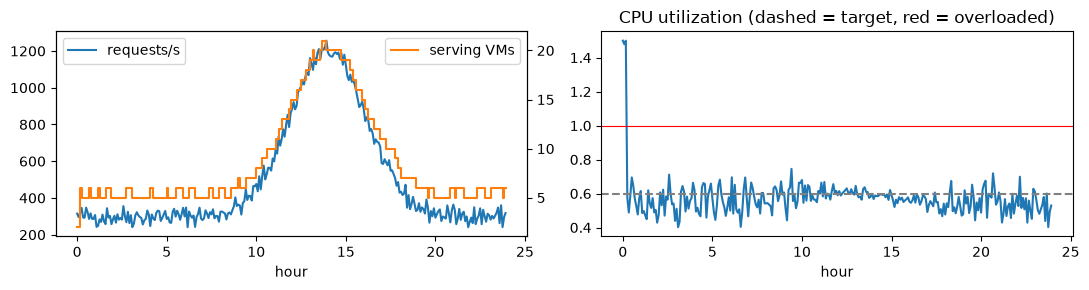

VM-hours used: 206; minutes above 100% util: 15


In [11]:
minutes = np.arange(0, 24 * 60, 5)                                      # one day in 5-minute steps
load = 300 + 900 * np.exp(-((minutes - 14 * 60) / 180) ** 2)            # requests/s, peak at 14:00
load += np.random.normal(0, 30, len(minutes)).clip(-60, 60)
CAP_PER_VM, TARGET, MIN_N, MAX_N, INIT_STEPS = 100, 0.6, 2, 30, 3      # 3 steps = 15 minutes warm-up

running, booting, history = MIN_N, [], []
for i, rps in enumerate(load):
    booting = [b - 1 for b in booting]
    running += sum(1 for b in booting if b <= 0); booting = [b for b in booting if b > 0]
    util = rps / (running * CAP_PER_VM)
    desired = int(np.clip(math.ceil(rps / (CAP_PER_VM * TARGET)), MIN_N, MAX_N))
    total = running + len(booting)
    if desired > total:
        booting += [INIT_STEPS] * (desired - total)          # scale out: new VMs start booting
    elif desired < running and i % 2 == 0:                   # scale in slowly (stabilisation)
        running = max(desired, running - 1)
    history.append((rps, running, min(util, 1.5)))

h = np.array(history)
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].plot(minutes / 60, h[:, 0], label="requests/s"); ax[0].set_xlabel("hour"); ax[0].legend(loc="upper left")
ax0b = ax[0].twinx(); ax0b.step(minutes / 60, h[:, 1], color="tab:orange", label="serving VMs"); ax0b.legend(loc="upper right")
ax[1].plot(minutes / 60, h[:, 2]); ax[1].axhline(TARGET, ls="--", color="gray"); ax[1].axhline(1.0, color="red", lw=0.8)
ax[1].set_title("CPU utilization (dashed = target, red = overloaded)"); ax[1].set_xlabel("hour")
plt.tight_layout(); plt.show()
print(f"VM-hours used: {h[:, 1].sum() * 5 / 60:.0f}; minutes above 100% util: {(h[:, 2] > 1).sum() * 5}")

**What just happened?** The group grows before the afternoon peak and shrinks afterwards. The short overload during the steepest ramp is the cost of the **initialization period**: VMs ordered now only serve 15 minutes later. Fixes: a lower target, **predictive autoscaling** (uses history), or a **scaling schedule**. Scaling in is deliberately slower than scaling out to avoid flapping.

### 5.2 Cloud Run: services, jobs, worker pools and functions

**What it is:** **Cloud Run** runs **containers** without servers to manage. You give it an image (or source code; it builds one with buildpacks), and it handles HTTPS, autoscaling (including **to zero**), revisions and traffic splitting.

**Simple analogy:** a taxi rank. Cars (instances) appear when passengers (requests) arrive and leave when the queue is empty.

| Cloud Run resource | What it runs | Scales | AI example |
|---|---|---|---|
| **Service** | HTTP/gRPC/WebSocket server at a stable URL | By requests (0 to N), **concurrency** = requests per instance (default 80) | Chat API, RAG backend, small model server (Cloud Run supports **NVIDIA GPUs** such as L4 for services) |
| **Job** | A container that runs **to completion**, optionally as many parallel **tasks** | You set task count and parallelism | Nightly embedding of new documents, batch evaluation, data prep (jobs can also use GPUs) |
| **Worker pool** | Always-on, non-HTTP background work | Manual (no request-based autoscaling by default) | Pub/Sub or Kafka pull consumers, queue workers |
| **Function** (**Cloud Run functions**, formerly Cloud Functions) | A single function from source, triggered by HTTP or events (via Eventarc) | Like a service | "New PDF uploaded to a bucket -> extract text" |

Other key facts: each deploy creates an immutable **revision**; you can split traffic (`--tag`, canary 5%); **min instances** avoid cold starts; billing is **request-based** (pay only while handling requests) or **instance-based** (pay for the instance lifetime, needed for background work); **Direct VPC egress** puts instances on your VPC; **IAM** (`roles/run.invoker`) can make a service private; source deploy builds via Cloud Build into Artifact Registry.

**When to use:** most stateless APIs and event handlers, agent backends, light GPU inference. **When not to:** you need many tightly coupled services with custom networking, DaemonSets, large multi-GPU nodes, or very long-lived stateful processes (use GKE or Compute Engine).

### 5.3 App Engine (legacy)

**App Engine** (Standard and Flexible environments) was Google's first platform-as-a-service (2008). It still runs, but new projects should use **Cloud Run**, which covers the same use cases with containers and more flexibility. Google publishes a migration guide from App Engine to Cloud Run. Only learn it if you maintain an older app.

### 5.4 GKE: Standard vs Autopilot

**What it is:** **Google Kubernetes Engine (GKE)** is managed Kubernetes. Google runs the control plane; you run workloads.

| | **Autopilot** mode | **Standard** mode |
|---|---|---|
| Who manages nodes | Google (node pools are invisible; you request resources per Pod) | You (node pools, machine types, upgrades settings) |
| Billing | Per Pod resource requests (with some exceptions such as specific hardware) | Per node VM |
| Security defaults | Hardened, some privileged workloads blocked | Up to you |
| GPUs/TPUs | Yes, by selecting a compute class / accelerator in the Pod spec | Yes, via GPU/TPU node pools |
| Best for | Most teams; less ops work | Special kernels, DaemonSets with host access, fine node-level tuning |

As of late 2026 GKE is **one offering without editions**: the features that used to be sold as **GKE Enterprise** (fleets, Config Sync, Policy Controller, multi-team management) became part of standard GKE in 2025 (see section 10.3). A **fleet** is a group of clusters managed together.

AI-specific GKE features worth knowing:
- **GPU and TPU node pools**, GPU time-sharing and multi-instance GPU, **Dynamic Workload Scheduler** via ProvisioningRequest / flex-start, **Kueue** for batch queueing, image streaming and secondary boot disks to start large model images faster.
- **GKE Inference Gateway** (GA): an extension of the Kubernetes **Gateway API** (the upstream **Inference Extension**, `InferencePool`) that routes LLM requests **model-aware**: it looks at each model server's KV-cache usage, queue length, **prefix-cache** hits and loaded LoRA adapters, instead of plain round-robin. The current docs describe it as "powered by **llm-d**".
- **GKE Inference Quickstart**: recommends a tested accelerator, model server (e.g. vLLM) and scaling configuration for a model and latency target, using Google's benchmark data, and can generate the manifests.

See [Kubernetes basics](../17_Docker/kubernetes/01_kubernetes.ipynb) and [Helm and GitOps](../17_Docker/03_helm_and_gitops.ipynb) for Kubernetes itself.

A tiny "which compute should I pick?" helper captures the usual decision path:

In [12]:
def pick_compute(stateless_http=True, needs_gpu=False, multi_gpu_node=False, many_services=False,
                 custom_os_or_kernel=False, runs_to_completion=False, event_driven_snippet=False):
    if custom_os_or_kernel:
        return "Compute Engine (VMs, MIGs)"
    if multi_gpu_node or (many_services and needs_gpu):
        return "GKE (Autopilot first; Standard if you need node-level control) + Inference Gateway for LLM serving"
    if many_services:
        return "GKE Autopilot"
    if event_driven_snippet:
        return "Cloud Run functions"
    if runs_to_completion:
        return "Cloud Run job" + (" with GPU" if needs_gpu else "")
    if stateless_http:
        return "Cloud Run service" + (" with GPU" if needs_gpu else "")
    return "Cloud Run worker pool (background consumer)"

scenarios = {
    "FastAPI RAG backend": dict(),
    "Small open model (8B, one L4)": dict(needs_gpu=True),
    "70B model, 8 GPUs per replica": dict(needs_gpu=True, multi_gpu_node=True),
    "Nightly re-embedding": dict(runs_to_completion=True),
    "Resize thumbnail on upload": dict(event_driven_snippet=True),
    "20 microservices + vector DB": dict(many_services=True),
    "Custom CUDA driver experiment": dict(custom_os_or_kernel=True),
    "Pub/Sub pull consumer": dict(stateless_http=False),
}
for name, kw in scenarios.items():
    print(f"{name:32s} -> {pick_compute(**kw)}")

FastAPI RAG backend              -> Cloud Run service
Small open model (8B, one L4)    -> Cloud Run service with GPU
70B model, 8 GPUs per replica    -> GKE (Autopilot first; Standard if you need node-level control) + Inference Gateway for LLM serving
Nightly re-embedding             -> Cloud Run job
Resize thumbnail on upload       -> Cloud Run functions
20 microservices + vector DB     -> GKE Autopilot
Custom CUDA driver experiment    -> Compute Engine (VMs, MIGs)
Pub/Sub pull consumer            -> Cloud Run worker pool (background consumer)


## 6. Storage and data

### 6.1 Cloud Storage

**What it is:** **Cloud Storage (GCS)** stores **objects** (files plus metadata) in **buckets**. Unlimited size, very high durability, accessed by API (`gs://bucket/path`).

**Simple analogy:** a huge warehouse of labelled boxes. You don't care which shelf a box is on, only its label.

**How it works:**
- **Location type**: **region** (lowest latency to compute in that region, cheapest), **dual-region** or **multi-region** (geo-redundant). Put training data in the **same region** as your GPUs/TPUs.
- **Storage classes** (same API and latency, different price trade-offs):

| Class | Minimum storage duration | Good for |
|---|---|---|
| **Standard** | none | hot data, training sets in use, model artifacts being served |
| **Nearline** | 30 days | accessed about once a month (old checkpoints) |
| **Coldline** | 90 days | about once a quarter (raw data you keep "just in case") |
| **Archive** | 365 days | compliance archives, rarely if ever read |

  Colder classes have lower storage prices but **retrieval fees** and an **early deletion** charge if you delete before the minimum duration.
- **Lifecycle rules** change class or delete objects by age, version count, etc. **Autoclass** moves objects between classes automatically based on access.
- **Object Versioning**, **soft delete** (recover deleted objects for a retention window), **retention policies / Bucket Lock** (WORM), **uniform bucket-level access** (IAM only, no per-object ACLs - recommended), **signed URLs** (temporary access to one object).
- For AI: **Cloud Storage FUSE** mounts a bucket as a file system in VMs, GKE Pods and Cloud Run (with file caching and parallel downloads for model weights), **Anywhere Cache** (zonal SSD read cache near accelerators), and **Hierarchical namespace** buckets (real folders, faster checkpoint renames).

Below, a lifecycle policy simulator with **made-up** prices shows why lifecycle rules matter for checkpoints.

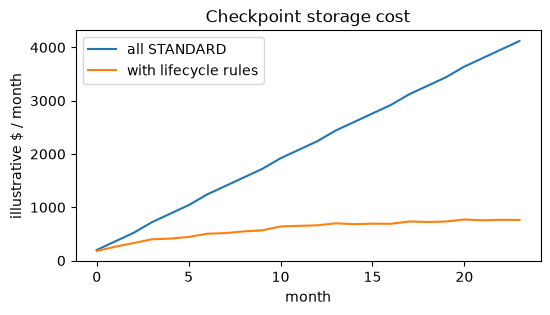

month 24: 4,120 vs 762 (illustrative units)


In [13]:
# ILLUSTRATIVE prices per GB-month (NOT real; check the pricing page). Ratios roughly mimic real tiers.
PRICE = {"STANDARD": 0.020, "NEARLINE": 0.010, "COLDLINE": 0.004, "ARCHIVE": 0.0012}
LIFECYCLE = [(30, "NEARLINE"), (90, "COLDLINE"), (365, "ARCHIVE")]   # (age in days, new class)

def class_at(age_days, rules=LIFECYCLE):
    cls = "STANDARD"
    for age, new in rules:
        if age_days >= age:
            cls = new
    return cls

# A training team writes 2 TB of checkpoints every week for 2 years and never deletes them
weeks = 104; gb_per_week = 2000
monthly_cost_no_rules, monthly_cost_rules = [], []
for month in range(1, 25):
    day = month * 30
    ages = [day - w * 7 for w in range(weeks) if w * 7 <= day]
    monthly_cost_no_rules.append(sum(gb_per_week * PRICE["STANDARD"] for _ in ages))
    monthly_cost_rules.append(sum(gb_per_week * PRICE[class_at(a)] for a in ages))

plt.figure(figsize=(6, 3))
plt.plot(monthly_cost_no_rules, label="all STANDARD"); plt.plot(monthly_cost_rules, label="with lifecycle rules")
plt.xlabel("month"); plt.ylabel("illustrative $ / month"); plt.legend(); plt.title("Checkpoint storage cost"); plt.show()
print(f"month 24: {monthly_cost_no_rules[-1]:,.0f} vs {monthly_cost_rules[-1]:,.0f} (illustrative units)")

```json
// The same rules as a real lifecycle config (gcloud storage buckets update gs://ckpts --lifecycle-file=rules.json)
{"rule": [
  {"action": {"type": "SetStorageClass", "storageClass": "NEARLINE"}, "condition": {"age": 30, "matchesStorageClass": ["STANDARD"]}},
  {"action": {"type": "SetStorageClass", "storageClass": "COLDLINE"}, "condition": {"age": 90, "matchesStorageClass": ["NEARLINE"]}},
  {"action": {"type": "Delete"}, "condition": {"age": 400}}
]}
```

Even better than moving checkpoints to colder classes: **delete** the ones you will never need (keep the best and the last few).

### 6.2 BigQuery, BigQuery ML and vector search

**What it is:** **BigQuery** is a serverless data warehouse. You write SQL; Google runs it on a large shared cluster. Storage and compute are separate.

**Simple analogy:** a library where you never see the shelves. You hand a question to the librarian army and pay for how many pages they had to read (on-demand) or for how many librarians you reserved (capacity).

**How it works:**
- **Datasets** (regional or multi-regional) contain **tables**, **views** and **materialized views**. Columnar storage (only the columns you select are read).
- **Pricing models**: **on-demand** (per TiB scanned) or **capacity-based** (BigQuery editions, pay for **slots** = units of compute, with autoscaling).
- **Partitioning** (by date/ingestion time/integer range) and **clustering** (sort by columns) cut bytes scanned. Always filter on the partition column.
- **BigQuery ML**: train and use models with SQL (`CREATE MODEL ... OPTIONS(model_type='logistic_reg')`, `ML.PREDICT`, `ML.EVALUATE`, ARIMA_PLUS forecasting, boosted trees, k-means, matrix factorization), call remote models such as Gemini (`ML.GENERATE_TEXT`, newer `AI.GENERATE` functions) and make embeddings (`ML.GENERATE_EMBEDDING`).
- **Vector search**: store embeddings in an `ARRAY<FLOAT64>` column, optionally `CREATE VECTOR INDEX` (IVF or TreeAH types), and query with the `VECTOR_SEARCH` table function. Good when your data already lives in BigQuery and latency of a second or so is fine.
- Also: **BigLake** / Iceberg tables over open formats in Cloud Storage, **BigQuery Omni** (query data in AWS/Azure), **Dataplex Universal Catalog** for governance, **Analytics Hub** for sharing, **BI Engine** for dashboards.

```sql
-- Real BigQuery SQL (not run here)
CREATE OR REPLACE MODEL `rag.doc_embedder` REMOTE WITH CONNECTION `us.vertex_conn`
  OPTIONS (ENDPOINT = 'text-embedding-model-name');             -- model name: check current docs
CREATE OR REPLACE TABLE rag.chunks_emb AS
  SELECT * FROM ML.GENERATE_EMBEDDING(MODEL `rag.doc_embedder`, (SELECT chunk_id, content FROM rag.chunks));
CREATE VECTOR INDEX chunks_idx ON rag.chunks_emb(ml_generate_embedding_result) OPTIONS(index_type = 'IVF');
SELECT base.chunk_id, distance
FROM VECTOR_SEARCH(TABLE rag.chunks_emb, 'ml_generate_embedding_result',
                   (SELECT ml_generate_embedding_result FROM query_emb), top_k => 3, distance_type => 'COSINE');
```

The toy shows (a) why partition filters save money and (b) what `VECTOR_SEARCH` returns, using pandas and numpy as stand-ins.

In [14]:
# (a) bytes scanned with and without a partition filter (toy table: 365 daily partitions)
days = pd.date_range("2026-01-01", periods=365, freq="D")
table = pd.DataFrame({"day": days, "bytes": np.random.randint(8, 12, 365) * 10**9})  # ~10 GB per day
full_scan = table["bytes"].sum()
pruned = table.loc[table["day"] >= "2026-12-25", "bytes"].sum()        # WHERE day >= '2026-12-25'
print(f"no partition filter : {full_scan / 1e12:.2f} TB scanned")
print(f"with partition filter: {pruned / 1e12:.3f} TB scanned  ({full_scan / pruned:.0f}x less)")

# (b) VECTOR_SEARCH-like output: base row + distance, top_k=3, cosine distance
chunks = pd.DataFrame({"chunk_id": [f"c{i}" for i in range(6)],
                       "content": ["refund policy 30 days", "shipping takes 5 days", "refunds need a receipt",
                                   "GPU quota increase steps", "TPU slices explained", "contact support by email"]})
rng = np.random.default_rng(SEED)
topic = {"refund": rng.normal(size=8), "ship": rng.normal(size=8), "gpu": rng.normal(size=8), "support": rng.normal(size=8)}
def fake_embed(text):   # stand-in for an embedding model: mix topic vectors by keyword
    v = sum(topic[k] for k in topic if k in text.lower() or (k == "gpu" and "tpu" in text.lower())) + 0.1 * rng.normal(size=8)
    return v / np.linalg.norm(v)
E = np.stack([fake_embed(t) for t in chunks.content])
q = fake_embed("how do refunds work")
dist = 1 - E @ q
print(chunks.assign(distance=dist.round(3)).nsmallest(3, "distance").to_string(index=False))

no partition filter : 3.41 TB scanned
with partition filter: 0.069 TB scanned  (49x less)
chunk_id                  content  distance
      c2   refunds need a receipt     0.001
      c0    refund policy 30 days     0.004
      c3 GPU quota increase steps     0.392


### 6.3 Operational databases

| Service | Type | Scale | Pick it when | AI angle |
|---|---|---|---|---|
| **Cloud SQL** | Managed MySQL, PostgreSQL, SQL Server | One primary (vertical scale) + read replicas, HA with standby | A normal app database, lift-and-shift | `pgvector` extension for small/medium vector search; Agent Platform integration |
| **AlloyDB for PostgreSQL** | PostgreSQL-compatible, Google storage layer, columnar engine | Higher throughput than Cloud SQL, read pools; **AlloyDB Omni** runs anywhere | Demanding Postgres OLTP + analytics | **AlloyDB AI**: `pgvector` plus a **ScaNN** vector index, calling embedding/LLM models from SQL (`google_ml_integration`), natural-language-to-SQL features |
| **Spanner** | Distributed relational, strong consistency, SQL (GoogleSQL or PostgreSQL dialect) | Horizontal, multi-region, 99.999% SLA option | Global systems of record (payments, inventory) needing scale + consistency | Vector search (KNN and ANN), full-text search, **Spanner Graph** (graph queries for GraphRAG); RAG Engine can use a managed Spanner as its vector DB |
| **Firestore** | Serverless document database (also Datastore mode; a MongoDB-compatible mode exists) | Automatic | Mobile/web app data, user profiles, chat history | Vector search on document fields (`find_nearest`), offline sync for apps, Firebase integration |
| **Bigtable** | Wide-column NoSQL (HBase API compatible) | Petabytes, single-digit ms at very high QPS | Time series, IoT, ad-tech, feature serving at huge scale | Low-latency online features; a common Feature Store backend; SQL support added |
| **Memorystore** | Managed in-memory: **Valkey**, Redis (incl. Redis Cluster), Memcached | Up to clusters of many shards | Caching, sessions, rate limiting, leaderboards | Semantic cache for LLM answers, vector search in Valkey/Redis |

Rule of thumb: start with **Cloud SQL / AlloyDB (Postgres + pgvector)** unless you need global scale (**Spanner**), app-centric documents (**Firestore**), or massive key-based throughput (**Bigtable**). See [NoSQL databases](../13_Databases/02_nosql/01_nosql_databases.ipynb) and [Vector databases](../22_ML_System_Design/05_vector_databases.ipynb).

In [15]:
def pick_database(relational=True, global_writes=False, huge_throughput_key_value=False,
                  mobile_sync=False, cache=False, heavy_analytics_on_oltp=False):
    if cache: return "Memorystore (Valkey/Redis)"
    if huge_throughput_key_value: return "Bigtable"
    if mobile_sync: return "Firestore"
    if relational and global_writes: return "Spanner"
    if relational and heavy_analytics_on_oltp: return "AlloyDB for PostgreSQL"
    if relational: return "Cloud SQL (PostgreSQL + pgvector)"
    return "Firestore"

for name, kw in {"RAG app metadata + 200k vectors": {}, "Global ticket booking": {"global_writes": True},
                 "Clickstream features, 1M reads/s": {"huge_throughput_key_value": True, "relational": False},
                 "Chat app with offline mobile": {"mobile_sync": True, "relational": False},
                 "LLM response cache": {"cache": True},
                 "Postgres OLTP + dashboards on same data": {"heavy_analytics_on_oltp": True}}.items():
    print(f"{name:42s} -> {pick_database(**kw)}")

RAG app metadata + 200k vectors            -> Cloud SQL (PostgreSQL + pgvector)
Global ticket booking                      -> Spanner
Clickstream features, 1M reads/s           -> Bigtable
Chat app with offline mobile               -> Firestore
LLM response cache                         -> Memorystore (Valkey/Redis)
Postgres OLTP + dashboards on same data    -> AlloyDB for PostgreSQL


## 7. Integration: messaging, events, schedules and pipelines

| Service | What it is (one line) | Analogy | Use it for |
|---|---|---|---|
| **Pub/Sub** | Global, at-least-once message bus: publishers send to a **topic**, each **subscription** gets a copy (pull, push to an HTTPS endpoint, or export to BigQuery / Cloud Storage) | A newspaper: one printing, many subscribers | Decoupling services, streaming ingestion, fan-out of "document uploaded" events |
| **Eventarc** | Routes **events** (from 100+ Google sources via Cloud Audit Logs, direct events like Cloud Storage, Pub/Sub, or your own) to Cloud Run, GKE, Workflows | A mail sorter that reads the envelope and forwards it | "When an object lands in `gs://inbox`, call the parsing service" |
| **Cloud Tasks** | A queue of **individual HTTP tasks** with per-queue **rate limits**, retries and scheduled delivery; the caller decides the target | A ticket machine at a deli: one at a time, at a controlled pace | Calling a rate-limited LLM API at most N per second; delayed work |
| **Cloud Scheduler** | Managed **cron**: calls an HTTP endpoint, Pub/Sub topic or Workflows on a schedule | An alarm clock | "Every night at 02:00, start the re-index job" |
| **Workflows** | Serverless **orchestration** of HTTP/API calls in YAML/JSON, with steps, conditions, retries, parallel branches and waiting for callbacks | A checklist a robot follows, step by step | Short business processes gluing APIs (call Document AI, then Gemini, then write to BigQuery) |
| **Cloud Composer** | Managed **Apache Airflow** (Composer 3 is current) | A full-time project manager with a Gantt chart | Complex data/ML pipelines with many DAGs, backfills, the Airflow ecosystem |
| **Dataflow** | Managed **Apache Beam** runner for batch and streaming, autoscaling workers, exactly-once streaming | A factory line that never stops | Streaming feature computation, large-scale preprocessing, Pub/Sub -> BigQuery |
| **Dataproc** | Managed **Spark/Hadoop** clusters and **Serverless for Apache Spark** | Renting a Spark cluster by the hour | Existing Spark jobs, PySpark feature engineering |

**Pub/Sub key concepts:** **ack deadline** (if a subscriber doesn't acknowledge in time, the message is redelivered), **at-least-once delivery** (duplicates are possible, so make handlers **idempotent**; an exactly-once option exists for pull subscriptions in one region), **ordering keys** (in-order delivery per key), **dead-letter topics** (after N failed delivery attempts), **retention** and **seek/replay**, **filters** on subscriptions, **schemas** (Avro/Protobuf).

The simulation shows redelivery and a dead-letter topic with a flaky subscriber.

In [16]:
def pubsub_sim(n_msgs=8, ack_deadline=10, max_attempts=5, fail_ids=(3,), flaky_ids=(5,), seed=SEED):
    rnd = random.Random(seed)
    queue = [{"id": i, "attempts": 0, "visible_at": 0} for i in range(n_msgs)]
    acked, dead, log, t = [], [], [], 0
    while queue and t < 200:
        ready = [m for m in queue if m["visible_at"] <= t]
        for m in ready:
            m["attempts"] += 1
            ok = not (m["id"] in fail_ids or (m["id"] in flaky_ids and rnd.random() < 0.7))
            if ok:
                acked.append(m["id"]); queue.remove(m)
                log.append(f"t={t:3d} msg {m['id']} attempt {m['attempts']}: processed, ACK")
            elif m["attempts"] >= max_attempts:
                dead.append(m["id"]); queue.remove(m)
                log.append(f"t={t:3d} msg {m['id']} attempt {m['attempts']}: failed -> dead-letter topic")
            else:   # no ack: becomes visible again after the ack deadline (plus retry backoff)
                m["visible_at"] = t + ack_deadline * m["attempts"]
                log.append(f"t={t:3d} msg {m['id']} attempt {m['attempts']}: failed, will be redelivered at t={m['visible_at']}")
        t += 1
    return acked, dead, log

acked, dead, log = pubsub_sim()
print("\n".join(l for l in log if "msg 3" in l or "msg 5" in l))
print(f"\nacked={sorted(acked)}  dead-lettered={dead}")

t=  0 msg 3 attempt 1: failed, will be redelivered at t=10
t=  0 msg 5 attempt 1: failed, will be redelivered at t=10
t= 10 msg 3 attempt 2: failed, will be redelivered at t=30
t= 10 msg 5 attempt 2: failed, will be redelivered at t=30
t= 30 msg 3 attempt 3: failed, will be redelivered at t=60
t= 30 msg 5 attempt 3: failed, will be redelivered at t=60
t= 60 msg 3 attempt 4: failed, will be redelivered at t=100
t= 60 msg 5 attempt 4: failed, will be redelivered at t=100
t=100 msg 3 attempt 5: failed -> dead-letter topic
t=100 msg 5 attempt 5: processed, ACK

acked=[0, 1, 2, 4, 5, 6, 7]  dead-lettered=[3]


```yaml
# Workflows: parse a new document, summarise it with a model endpoint, store the result (sketch, not run)
main:
  params: [event]
  steps:
    - parse:
        call: http.post
        args: {url: https://parser-xyz.a.run.app/parse, auth: {type: OIDC}, body: {uri: ${event.data.name}}}
        result: parsed
    - summarise:
        try:
          call: http.post
          args: {url: https://summariser-xyz.a.run.app/v1/summarise, auth: {type: OIDC}, body: ${parsed.body}}
          result: summary
        retry: {predicate: ${http.default_retry}, max_retries: 5, backoff: {initial_delay: 2, max_delay: 60, multiplier: 2}}
    - store:
        call: googleapis.bigquery.v2.tabledata.insertAll
        args: {projectId: rag-prod, datasetId: rag, tableId: summaries, body: {rows: [{json: ${summary.body}}]}}
```

**Which orchestrator?** Workflows for short API glue (seconds to hours, cheap, no servers). Cloud Composer for big data/ML DAGs, scheduling, backfills and Airflow operators. Agent Platform Pipelines (Kubeflow Pipelines) for ML training pipelines with lineage and artifact tracking (see the AI notebook). Cloud Scheduler + Cloud Run job for "one container every night".

## 8. Observability: Cloud Monitoring, Logging and Trace

**What it is:** **Google Cloud Observability** is the umbrella for **Cloud Monitoring** (metrics, dashboards, uptime checks, alerting, SLOs), **Cloud Logging** (log storage, search with Logging query language, **Log Analytics** with SQL), **Cloud Trace** (distributed tracing, OpenTelemetry native), **Error Reporting** and **Cloud Profiler**. Managed Service for Prometheus stores Prometheus metrics from GKE.

**Simple analogy:** the dashboard (metrics), the flight recorder (logs) and the parcel tracking number (traces) of your system.

**How it works:**
- Every Google service writes **platform metrics** and **audit logs** (Admin Activity logs are always on; **Data Access** logs must be enabled for most services, and are important for AI data).
- The **Log Router** sends logs through **sinks** to **log buckets** (with retention), BigQuery, Cloud Storage or Pub/Sub; **exclusion filters** drop noisy logs to save cost.
- **Alerting policies** fire on metric conditions or log-based metrics and notify channels (email, PagerDuty, Pub/Sub ...).
- **SLOs** can be defined on a service (e.g. 99.5% of requests succeed over 28 days) with **burn-rate alerts**.
- For LLM apps, send OpenTelemetry GenAI spans (prompt/response token counts, model name, latency) to Cloud Trace. See [Observability hands-on](../15_MLOps/16_observability_hands_on.ipynb).

The toy computes a multi-window **burn-rate** alert, the method recommended in the Google SRE workbook.

total error ratio today: 0.6073% (budget 0.50%)
page fired at minute 928 (15:28)


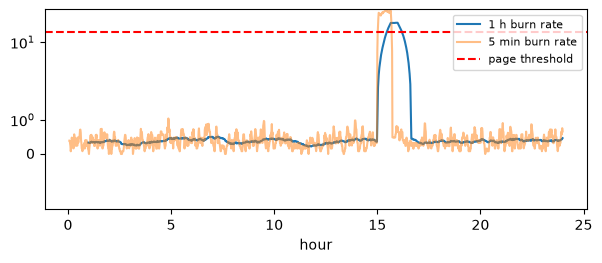

In [17]:
# One day of per-minute traffic for a chat API, with an incident at 15:00-15:40
mins = 24 * 60
reqs = np.random.poisson(500, mins)
err_rate = np.full(mins, 0.002); err_rate[900:940] = 0.15            # 15% errors during the incident
errs = np.random.binomial(reqs, err_rate)
SLO = 0.995; budget = 1 - SLO                                           # 0.5% of requests may fail

def burn_rate(window):
    e = pd.Series(errs).rolling(window).sum(); r = pd.Series(reqs).rolling(window).sum()
    return (e / r) / budget          # 1.0 = spending the budget exactly at the allowed pace

long_w, short_w = burn_rate(60), burn_rate(5)
alert = (long_w > 14.4) & (short_w > 14.4)       # the "page someone" pair: 1 h and 5 min windows
first = int(np.argmax(alert.values)) if alert.any() else None
print(f"total error ratio today: {errs.sum() / reqs.sum():.4%} (budget {budget:.2%})")
print(f"page fired at minute {first} ({first // 60:02d}:{first % 60:02d})" if first else "no page")

plt.figure(figsize=(7, 2.6))
plt.plot(np.arange(mins) / 60, long_w, label="1 h burn rate"); plt.plot(np.arange(mins) / 60, short_w, alpha=0.5, label="5 min burn rate")
plt.axhline(14.4, ls="--", color="red", label="page threshold"); plt.yscale("symlog"); plt.xlabel("hour"); plt.legend(fontsize=8); plt.show()

## 9. CI/CD and Infrastructure as Code

### 9.1 Cloud Build, Artifact Registry, Cloud Deploy

- **Cloud Build**: serverless CI. A `cloudbuild.yaml` lists **steps**, each a container (`docker build`, `pytest`, `gcloud run deploy`). Triggers from GitHub/GitLab/Bitbucket, private pools inside your VPC.
- **Artifact Registry**: stores container images and language packages (Python, npm, Maven, apt, ...), with **vulnerability scanning** and remote/virtual repositories (proxy and cache PyPI or Docker Hub). It **replaced Container Registry** (`gcr.io`), which Google shut down in 2025; `gcr.io` names can be served from Artifact Registry repositories during migration. Image path: `REGION-docker.pkg.dev/PROJECT/REPO/IMAGE:TAG`.
- **Cloud Deploy**: managed **continuous delivery** to GKE, Cloud Run and others: a **delivery pipeline** of **targets** (dev -> staging -> prod) with promotions, approvals, canary deployments and rollbacks.

```yaml
# cloudbuild.yaml (sketch)
steps:
  - name: python:3.12
    entrypoint: bash
    args: ["-c", "pip install -r requirements.txt && pytest -q"]
  - name: gcr.io/cloud-builders/docker
    args: ["build", "-t", "us-central1-docker.pkg.dev/$PROJECT_ID/apps/rag-api:$SHORT_SHA", "."]
  - name: gcr.io/cloud-builders/docker
    args: ["push", "us-central1-docker.pkg.dev/$PROJECT_ID/apps/rag-api:$SHORT_SHA"]
  - name: gcr.io/google.com/cloudsdktool/cloud-sdk
    args: ["gcloud", "run", "deploy", "rag-api", "--region=us-central1",
           "--image=us-central1-docker.pkg.dev/$PROJECT_ID/apps/rag-api:$SHORT_SHA"]
```
(The `gcr.io/cloud-builders/...` names are Google's builder images, still served under that path.)

### 9.2 Infrastructure Manager, Terraform and Config Connector

| Tool | What it is | When |
|---|---|---|
| **Terraform** (`hashicorp/google` and `google-beta` providers) or **OpenTofu** | Declarative HCL files -> `plan` -> `apply`; state file records what exists | The default for GCP IaC; same tool across clouds |
| **Infrastructure Manager (Infra Manager)** | Google-managed service that **runs Terraform for you**: each **deployment** has **revisions**, **previews** (plans), state stored per revision; it runs as a short-lived Cloud Build job; sources from Git, Cloud Storage or local | You want Terraform without running your own runners or state bucket |
| **Config Connector** | A Kubernetes add-on: GCP resources as **Kubernetes custom resources** (KRM YAML), continuously reconciled | Teams that manage everything through Kubernetes / GitOps |
| **Cloud Deployment Manager** | Google's old YAML/Jinja IaC. **Support discontinued 1 April 2026** (the deprecation page also mentions 31 March 2026 as the migration deadline); new users blocked from 30 June 2026; **turned down 30 June 2027**. Migrate with the **DM Convert** tool to Terraform / Infra Manager | Only to migrate away |

```hcl
# main.tf (sketch)
provider "google" {
  project = "rag-prod-7f3a"
  region  = "us-central1"
}

resource "google_storage_bucket" "docs" {
  name                        = "rag-prod-7f3a-docs"
  location                    = "US-CENTRAL1"
  uniform_bucket_level_access = true
  lifecycle_rule {
    condition { age = 90 }
    action {
      type          = "SetStorageClass"
      storage_class = "COLDLINE"
    }
  }
}

resource "google_service_account" "rag_api" { account_id = "rag-api" }

resource "google_storage_bucket_iam_member" "reader" {
  bucket = google_storage_bucket.docs.name
  role   = "roles/storage.objectViewer"
  member = "serviceAccount:${google_service_account.rag_api.email}"
}

resource "google_cloud_run_v2_service" "api" {
  name     = "rag-api"
  location = "us-central1"
  template {
    service_account = google_service_account.rag_api.email
    containers { image = "us-central1-docker.pkg.dev/rag-prod-7f3a/apps/rag-api:v1" }
  }
}
```

```bash
# Infra Manager (not run here)
gcloud infra-manager deployments apply projects/rag-prod-7f3a/locations/us-central1/deployments/rag-stack \
  --service-account=projects/rag-prod-7f3a/serviceAccounts/infra@rag-prod-7f3a.iam.gserviceaccount.com \
  --git-source-repo=https://github.com/acme/infra --git-source-directory=rag --git-source-ref=main
```

```yaml
# Config Connector: the same bucket as a Kubernetes object
apiVersion: storage.cnrm.cloud.google.com/v1beta1
kind: StorageBucket
metadata: {name: rag-prod-7f3a-docs, namespace: rag}
spec: {location: US-CENTRAL1, uniformBucketLevelAccess: true}
```

All of these tools share one idea: compare **desired** state with **actual** state and compute a plan. The toy does exactly that, including **drift** (someone changed a resource by hand).

In [18]:
desired = {
    "bucket/rag-docs": {"location": "US-CENTRAL1", "uniform_access": True, "class": "STANDARD"},
    "sa/rag-api": {"display": "RAG API"},
    "run/rag-api": {"image": "rag-api:v2", "min_instances": 1},
}
actual = {
    "bucket/rag-docs": {"location": "US-CENTRAL1", "uniform_access": False, "class": "STANDARD"},  # drift!
    "run/rag-api": {"image": "rag-api:v1", "min_instances": 1},
    "vm/old-notebook": {"machine": "n2-standard-8"},                                              # not in code
}

def plan(desired, actual):
    steps = []
    for k in sorted(desired.keys() | actual.keys()):
        if k not in actual:
            steps.append(("+ create", k, desired[k]))
        elif k not in desired:
            steps.append(("- destroy", k, actual[k]))
        else:
            diff = {f: (actual[k].get(f), v) for f, v in desired[k].items() if actual[k].get(f) != v}
            if diff:
                steps.append(("~ update", k, {f: f"{a} -> {b}" for f, (a, b) in diff.items()}))
    return steps

for action, key, detail in plan(desired, actual):
    print(f"{action:10s} {key:18s} {detail}")
print("\nPlan: review it, then apply. Never apply without reading the destroy lines.")

~ update   bucket/rag-docs    {'uniform_access': 'False -> True'}
~ update   run/rag-api        {'image': 'rag-api:v1 -> rag-api:v2'}
+ create   sa/rag-api         {'display': 'RAG API'}
- destroy  vm/old-notebook    {'machine': 'n2-standard-8'}

Plan: review it, then apply. Never apply without reading the destroy lines.


## 10. Security services

### 10.1 Secret Manager and Cloud KMS

- **Secret Manager** stores API keys, passwords and certificates as **secrets** with immutable **versions** (`projects/P/secrets/openai-key/versions/3`, or the alias `latest`). Access needs `roles/secretmanager.secretAccessor`. Supports rotation notifications (via Pub/Sub), regional secrets, CMEK and mounting into Cloud Run / GKE as env vars or files. Pin a **specific version** in production so a bad new value does not roll out everywhere at once.
- **Cloud KMS** manages **encryption keys**: **key rings** (regional containers) hold **keys**, which have **key versions**; one is **primary** (used for new encryption). Protection levels: software, **Cloud HSM** (hardware), **Cloud External Key Manager (EKM)** (key stays outside Google). **CMEK** (customer-managed encryption keys) lets services such as Cloud Storage, BigQuery, Agent Platform and GKE encrypt your data with *your* KMS key, so disabling the key makes the data unreadable. **Autokey** creates CMEK keys automatically per resource.
- **Envelope encryption**: data is encrypted with a local **data encryption key (DEK)**; the DEK is then encrypted ("wrapped") by a **key encryption key (KEK)** in KMS. You store the wrapped DEK next to the data. Rotating the KEK does not require re-encrypting all data.

The toy below shows the envelope pattern and version rotation. **The "cipher" is a toy XOR stream for illustration only; never use it for real data.**

In [19]:
def toy_stream_xor(key: bytes, data: bytes) -> bytes:
    # NOT real cryptography: XOR with a SHA-256 based keystream, only to show the data flow
    out, counter = bytearray(), 0
    while len(out) < len(data):
        out += hashlib.sha256(key + counter.to_bytes(8, "big")).digest(); counter += 1
    return bytes(a ^ b for a, b in zip(data, out))

class ToyKMSKey:
    def __init__(self):
        self.versions = {1: hashlib.sha256(b"kek-v1").digest()}   # toy key material
        self.primary = 1
    def rotate(self):
        v = max(self.versions) + 1
        self.versions[v] = hashlib.sha256(f"kek-v{v}".encode()).digest(); self.primary = v
    def encrypt(self, plaintext):              # wrap a DEK
        return {"key_version": self.primary, "ct": toy_stream_xor(self.versions[self.primary], plaintext)}
    def decrypt(self, wrapped):                # old versions still decrypt old data
        return toy_stream_xor(self.versions[wrapped["key_version"]], wrapped["ct"])

kek = ToyKMSKey()
dek = hashlib.sha256(b"random-dek-for-file-1").digest()
record = {"ciphertext": toy_stream_xor(dek, b"patient note: allergic to penicillin"),
          "wrapped_dek": kek.encrypt(dek)}
kek.rotate()                                                  # new primary version 2
new_record_dek = kek.encrypt(hashlib.sha256(b"dek-2").digest())
print("old record wrapped with version", record["wrapped_dek"]["key_version"], "| new data uses version", new_record_dek["key_version"])
plain = toy_stream_xor(kek.decrypt(record["wrapped_dek"]), record["ciphertext"])
print("decrypted old record:", plain.decode())

old record wrapped with version 1 | new data uses version 2
decrypted old record: patient note: allergic to penicillin


### 10.2 Security Command Center, Binary Authorization and friends

| Service | What it does | Analogy |
|---|---|---|
| **Security Command Center (SCC)** | Central security and risk dashboard: misconfiguration findings (Security Health Analytics: public buckets, open firewall, keys), threat detection (Event Threat Detection, Container Threat Detection), vulnerability findings, attack path simulation, compliance reports. Standard, Premium and **Enterprise** tiers (Enterprise adds SIEM/SOAR and multicloud). **AI Protection** in SCC discovers AI assets (models, agents, datasets) and connects to Model Armor findings | The building's security control room |
| **Binary Authorization** | Deploy-time policy for GKE and Cloud Run: only run container images that have the required **attestations** (e.g. "built by our Cloud Build", "vulnerability scan passed"), referenced by **digest** | A bouncer checking signed passes at the door |
| **Artifact Analysis** | Vulnerability scanning and metadata (SBOM, provenance) for images in Artifact Registry | X-ray of every parcel |
| **Sensitive Data Protection** (formerly Cloud DLP) | Finds and de-identifies PII (credit cards, names, IDs) in text, storage and BigQuery; also used by Model Armor | A redaction pen |
| **Identity-Aware Proxy (IAP)** | Puts Google sign-in + IAM in front of web apps and SSH/TCP, without a VPN | A receptionist who checks your badge before you reach the office |
| **Certificate Manager**, **Cloud HSM**, **Assured Workloads** | TLS certificates; hardware keys; compliance regimes (FedRAMP, EU sovereignty controls) | |

The Binary Authorization toy:

In [20]:
ATTESTATIONS = {   # image digest -> set of attestors that signed it
    "sha256:aaa111": {"built-by-cloud-build", "vuln-scan-passed"},
    "sha256:bbb222": {"built-by-cloud-build"},
}
POLICY = {"prod-cluster": {"built-by-cloud-build", "vuln-scan-passed"}, "dev-cluster": {"built-by-cloud-build"}}

def admit(image_ref, target):
    if "@sha256:" not in image_ref:
        return "DENY: use an immutable digest, not a tag"
    digest = image_ref.split("@")[1]
    missing = POLICY[target] - ATTESTATIONS.get(digest, set())
    return "ALLOW" if not missing else f"DENY: missing attestations {sorted(missing)}"

for ref, tgt in [("us-docker.pkg.dev/p/apps/rag@sha256:aaa111", "prod-cluster"),
                 ("us-docker.pkg.dev/p/apps/rag@sha256:bbb222", "prod-cluster"),
                 ("us-docker.pkg.dev/p/apps/rag@sha256:bbb222", "dev-cluster"),
                 ("us-docker.pkg.dev/p/apps/rag:latest", "dev-cluster")]:
    print(f"{ref.split('/')[-1]:22s} -> {tgt:12s}: {admit(ref, tgt)}")

rag@sha256:aaa111      -> prod-cluster: ALLOW
rag@sha256:bbb222      -> prod-cluster: DENY: missing attestations ['vuln-scan-passed']
rag@sha256:bbb222      -> dev-cluster : ALLOW
rag:latest             -> dev-cluster : DENY: use an immutable digest, not a tag


### 10.3 Hybrid and multicloud: Google Distributed Cloud, fleets, attached clusters

- **Google Distributed Cloud (GDC)** brings Google Cloud services to places outside Google's regions: **GDC connected** (Google-managed hardware racks or servers at your site or edge, connected to Google Cloud), **GDC air-gapped** (fully disconnected, for defence and regulated sectors, including AI services such as Gemini models and Agent Platform on GDC), and **software-only** editions for **VMware** and **bare metal** (formerly "Anthos clusters on VMware / bare metal", then "GKE Enterprise on ..." ).
- **Anthos -> GKE Enterprise -> GKE**: the multicloud management features were sold as Anthos (2019), renamed GKE Enterprise (2023), and in 2025 those features (fleets, Config Sync, Policy Controller, multi-team management, Connect gateway) were folded into standard GKE; the GKE docs now say GKE "is a single offering, without different editions or tiers". Some items (for example Cloud Service Mesh, multi-cluster gateways, Binary Authorization) are separate products.
- **GKE attached clusters** / GKE Multi-Cloud register EKS, AKS and other conformant Kubernetes clusters into a **fleet**, so you can apply the same configuration and policy everywhere.

**When to use:** data residency or latency needs that a public region cannot meet, factories and retail edge sites, air-gapped requirements, or a consistent platform across clouds. **When not to:** if a public Google Cloud region meets your needs, it is far simpler.

## 11. Billing: budgets and committed use discounts

**How billing is wired:** a **Cloud Billing account** (linked to a payments profile) pays for one or more **projects**. Roles: Billing Account Administrator / User / Viewer. Export detailed billing data to **BigQuery** (standard, detailed usage and pricing exports) and analyse it with SQL; use **labels** to split cost by team or app.

| Discount / control | How it works | Good for |
|---|---|---|
| **Sustained use discounts** | Automatic discount for some VM families that run most of the month | Nothing to do; it just happens (not all machine series) |
| **Committed use discounts (CUDs)** | Commit for **1 or 3 years**. **Resource-based**: a fixed amount of vCPU/memory/GPU/local SSD in a region. **Spend-based** (flexible): a minimum hourly spend on eligible services (Compute Engine, GKE, Cloud Run, Cloud SQL, ...) | Steady baseline load you are sure about |
| **Spot VMs** | Deep discount, can be stopped any time | Fault-tolerant batch and training with checkpoints |
| **Reservations / future reservations** | Guarantee capacity (especially GPUs) in a zone; you pay whether used or not, CUDs can apply | Launches, training runs that must start on a date |
| **Budgets and alerts** | Set an amount per billing account / project / label; thresholds (e.g. 50%, 90%, 100% of actual or **forecasted** spend) send email or **Pub/Sub** messages | Every project, from day one. A budget **does not cap** spend by itself; a Pub/Sub-triggered function can disable billing or scale things down if you really need a hard stop |
| **Quotas** | Per-project limits on resources (GPUs per region, API requests per minute) | Preventing runaway usage; request increases ahead of time for GPUs |

Below: a CUD break-even calculator and a budget-forecast alert. **All prices and discount levels are made up**; use the official pricing calculator.

1-year CUD breaks even at 63% utilization
3-year CUD breaks even at 45% utilization


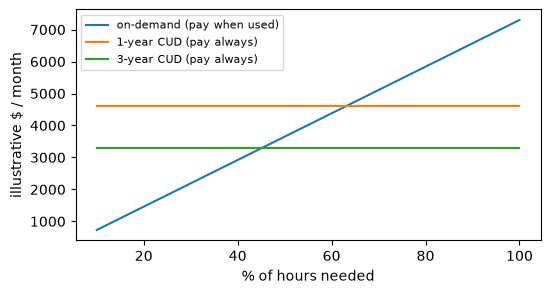

day 10: spent    7,058  forecast   21,173  forecast alerts: ['50%']
day 15: spent   10,209  forecast   20,418  forecast alerts: ['50%']
day 20: spent   15,892  forecast   23,837  forecast alerts: ['50%']
day 25: spent   24,356  forecast   29,228  forecast alerts: ['50%', '90%', '100%']


In [21]:
ON_DEMAND_HOURLY = 10.0                     # illustrative $/hour for a GPU VM
CUD = {"1-year": 0.37, "3-year": 0.55}     # illustrative discount levels (NOT official)
util = np.linspace(0.1, 1.0, 91)           # fraction of the month the VM is actually needed
hours = 730
cost_od = ON_DEMAND_HOURLY * hours * util
plt.figure(figsize=(6, 3))
plt.plot(util * 100, cost_od, label="on-demand (pay when used)")
for name, d in CUD.items():
    committed = ON_DEMAND_HOURLY * (1 - d) * hours * np.ones_like(util)   # you pay 24x7
    plt.plot(util * 100, committed, label=f"{name} CUD (pay always)")
    print(f"{name} CUD breaks even at {100 * (1 - d):.0f}% utilization")
plt.xlabel("% of hours needed"); plt.ylabel("illustrative $ / month"); plt.legend(fontsize=8); plt.show()

# Budget forecast: linear projection of month-to-date spend
budget = 28_000
daily = np.random.normal(700, 120, 30).clip(300)
daily[18:] *= 2.5                                            # someone left a big GPU job running
for day in [10, 15, 20, 25]:
    mtd = daily[:day].sum(); forecast = mtd / day * 30
    alerts = [f"{int(p * 100)}%" for p in (0.5, 0.9, 1.0) if forecast >= p * budget]
    print(f"day {day:2d}: spent {mtd:8,.0f}  forecast {forecast:8,.0f}  forecast alerts: {alerts or '-'}")

## 12. `gcloud` and Cloud Shell cheat sheet

```bash
gcloud init                                   # log in, choose a default project and region
gcloud auth login                             # user credentials for the CLI
gcloud auth application-default login         # credentials for client libraries on your laptop (ADC)
gcloud config set project rag-prod-7f3a
gcloud services enable run.googleapis.com aiplatform.googleapis.com artifactregistry.googleapis.com
gcloud projects get-iam-policy rag-prod-7f3a --format=json
gcloud iam service-accounts create rag-api
gcloud run deploy rag-api --source . --region us-central1 --service-account rag-api@rag-prod-7f3a.iam.gserviceaccount.com --no-allow-unauthenticated
gcloud storage buckets create gs://rag-prod-7f3a-docs --location=us-central1 --uniform-bucket-level-access
gcloud container clusters create-auto rag-gke --region us-central1      # GKE Autopilot cluster
gcloud logging read 'resource.type="cloud_run_revision" severity>=ERROR' --limit 20
gcloud billing budgets create --billing-account=XXXX --display-name=rag --budget-amount=2000USD --threshold-rule=percent=0.9
```

**Cloud Shell** is a free browser VM with `gcloud`, `kubectl`, `terraform`, Docker and an editor, authenticated as you. `gcloud storage` replaced the older `gsutil` for most tasks; `bq` is the BigQuery CLI.

The cell below is **guarded**: it only runs if `gcloud` is installed, and even then only prints the version.

In [22]:
import shutil, subprocess
if shutil.which("gcloud"):
    out = subprocess.run(["gcloud", "--version"], capture_output=True, text=True, timeout=30)
    print(out.stdout.splitlines()[0] if out.stdout else "gcloud found")
else:
    print("skipped: needs the gcloud CLI (Google Cloud SDK) and a Google Cloud account")

skipped: needs the gcloud CLI (Google Cloud SDK) and a Google Cloud account


## 13. Putting it together: a reference architecture for an AI app

A private RAG / agent API for internal users, built from the services above. The model side (Agent Platform, Model Armor, Vector Search) is explained in [notebook 11](11_gcp_ai_gemini_enterprise_agent_platform.ipynb).

```mermaid
flowchart LR
    U["Users (browser)"] --> LB["Global external Application LB + Cloud Armor (+ IAP)"]
    LB --> RUN["Cloud Run service: RAG/agent API (service account rag-api)"]
    RUN -->|Secret Manager| SEC[(Secrets)]
    RUN -->|PSC endpoint| AP["Agent Platform: Gemini + Model Armor"]
    RUN --> DB[("AlloyDB / Cloud SQL + pgvector")]
    RUN --> MEM[("Memorystore: cache")]
    GCS[("Cloud Storage: raw docs")] -->|Eventarc| ING["Cloud Run job: parse + embed"]
    ING --> DB
    ING --> BQ[("BigQuery: analytics, eval results")]
    RUN -->|logs, traces| OBS["Cloud Logging / Monitoring / Trace"]
    OBS --> BQ
    subgraph Perimeter["VPC Service Controls perimeter (rag-prod)"]
      RUN
      ING
      GCS
      BQ
      AP
      DB
    end
    CI["GitHub Actions via Workload Identity Federation"] --> CB["Cloud Build -> Artifact Registry -> Cloud Deploy"]
    CB --> RUN
    TF["Terraform / Infra Manager"] -.creates.-> Perimeter
```

### Google Cloud Well-Architected Framework checklist

The framework (formerly called the Architecture Framework) has **six pillars**: operational excellence; security, privacy and compliance; reliability; cost optimization; performance optimization; sustainability. It also has an **AI and ML perspective**. The code turns a checklist into a score so a design review can see gaps at a glance.

In [23]:
CHECKLIST = {
    "Operational excellence": {"IaC for every resource (Terraform/Infra Manager)": True, "CI/CD with Cloud Deploy": True,
                               "SLOs + burn-rate alerts": True, "runbooks for incidents": False},
    "Security, privacy, compliance": {"no service account keys (WIF, attached SAs)": True, "VPC-SC perimeter": True,
                                      "CMEK on sensitive data": False, "Model Armor on prompts/responses": True,
                                      "Data Access audit logs on": False},
    "Reliability": {"multi-zone or regional services": True, "backups + tested restore": False,
                    "retries with backoff, idempotent consumers": True, "quota headroom for GPUs": False},
    "Cost optimization": {"budgets + alerts per project": True, "labels on all resources": True,
                          "lifecycle rules on buckets": True, "CUDs only for steady baseline": False},
    "Performance optimization": {"data colocated with compute": True, "caching (CDN/Memorystore)": True,
                                 "load test before launch": False},
    "Sustainability": {"low-carbon region considered": False, "scale to zero when idle": True},
}
rows = [{"pillar": p, "score": f"{sum(v.values())}/{len(v)}", "gaps": "; ".join(k for k, ok in v.items() if not ok) or "-"}
        for p, v in CHECKLIST.items()]
print(pd.DataFrame(rows).to_string(index=False))

                       pillar score                                              gaps
       Operational excellence   3/4                            runbooks for incidents
Security, privacy, compliance   3/5 CMEK on sensitive data; Data Access audit logs on
                  Reliability   2/4 backups + tested restore; quota headroom for GPUs
            Cost optimization   3/4                     CUDs only for steady baseline
     Performance optimization   2/3                           load test before launch
               Sustainability   1/2                      low-carbon region considered


## 14. How to try it for real (cheaply and safely)

- **Google Cloud Free Program**: new accounts get trial credits, and an **Always Free** tier covers small monthly usage of several products (for example small Cloud Run, Cloud Storage, BigQuery query and storage amounts, an e2-micro VM in some regions). Limits change; check the free-tier page.
- **Set a budget alert first**, and put labs in their own project so you can delete the whole project afterwards (`gcloud projects delete`).
- **Cloud Shell** gives you a terminal with everything installed, at no cost.
- **Local emulators** (no account needed): `gcloud emulators` for **Pub/Sub**, **Firestore**, **Datastore**, **Bigtable** and **Spanner**; the **Firebase Local Emulator Suite**; Cloud Run functions **Functions Framework** to run a function locally; the community `fake-gcs-server` for Cloud Storage (third-party); `kind` or `minikube` for Kubernetes practice before GKE.
- **Terraform without risk**: `terraform plan` against a lab project, or `terraform validate` with no credentials at all.
- **Google Cloud Skills Boost** labs give you a temporary project for an hour, so mistakes cost nothing.

## 15. Certification topic map

| Exam (Google Cloud certification) | Sections of this notebook |
|---|---|
| **Associate Cloud Engineer** (set up environments, plan/implement, operate, configure access) | 2 hierarchy, 3 IAM and service accounts, 4.1-4.2 VPC and firewall, 5 compute, 6.1 storage, 8 logging/monitoring, 11 billing, 12 gcloud |
| **Professional Cloud Architect** (design and plan, manage infrastructure, security and compliance, analyse and optimise processes, manage implementations, operations excellence; uses the Well-Architected Framework and case studies) | all sections, especially 4.3 PSC/VPC-SC, 5 compute choice, 6.3 database choice, 10 security, 13 reference architecture + Well-Architected checklist |
| **Professional Cloud Security Engineer** | 3 IAM, WIF, 4.2-4.4 firewall/VPC-SC/Cloud Armor, 10 KMS/Secret Manager/SCC/Binary Authorization |
| **Professional Cloud Network Engineer** | 4 networking (CIDR planning, Shared VPC, PSC, load balancing, NAT, DNS, Interconnect) |
| **Professional Cloud DevOps Engineer** | 8 SLOs and burn rate, 9 CI/CD and IaC, 5.2 Cloud Run revisions |
| **Professional Data Engineer** | 6 storage and databases, 7 Pub/Sub, Dataflow, Composer |
| **Professional Machine Learning Engineer** | 5 GPU compute and GKE inference, 6 data services; most ML content is in notebook 11 |

Exam guides change; check the official guide on each certification page before studying.

## 16. Recap: cheat sheet

| Topic | Remember this |
|---|---|
| Hierarchy | Org -> folders -> projects -> resources. IAM allow policies inherit as a **union**; Org Policy is a guard-rail that can be inherited, merged or replaced |
| IAM | Principal + role + resource. Prefer predefined roles on groups at the smallest scope; deny policies run first; default is deny |
| Service accounts | Identity for code; attach them, impersonate them, avoid keys |
| WIF | Exchange an outside OIDC/SAML token for a short-lived Google token; always set an attribute condition |
| VPC | Global network, regional subnets, plan CIDRs to avoid overlaps; secondary ranges for GKE |
| Firewall | Lower priority number wins; implied deny-ingress / allow-egress; hierarchical policies first, `goto_next` delegates |
| Shared VPC / PSC / VPC-SC | Central network for many projects / private IP to a service / perimeter against data exfiltration |
| Edge | Global Application LB + Cloud CDN + Cloud Armor; Cloud NAT for private egress; Cloud DNS; HA VPN / Interconnect for hybrid |
| Compute | Cloud Run first (services, jobs, worker pools, functions); GKE Autopilot for many services and multi-GPU serving; Compute Engine for full control |
| Storage | Standard / Nearline (30 d) / Coldline (90 d) / Archive (365 d) + lifecycle rules; keep data near accelerators |
| Data | BigQuery for analytics, BQML and vector search; Cloud SQL / AlloyDB for Postgres + pgvector; Spanner global; Firestore documents; Bigtable huge key-value; Memorystore cache |
| Integration | Pub/Sub at-least-once (idempotent handlers, DLQ); Eventarc for events; Cloud Tasks for rate-limited calls; Scheduler for cron; Workflows / Composer for orchestration |
| Ops | Monitoring + Logging + Trace; SLOs with multi-window burn-rate alerts |
| IaC | Terraform / Infra Manager; Config Connector for KRM; Deployment Manager is discontinued |
| Security | Secret Manager, Cloud KMS (CMEK, envelope encryption), SCC, Binary Authorization, Artifact Registry (replaced Container Registry) |
| Billing | Budgets alert but do not cap; CUDs for steady baseline; Spot for fault-tolerant work; billing export to BigQuery |

## 17. Interview questions

1. **How do IAM permissions combine across the resource hierarchy?** Allow policies on the org, folders, project and resource are combined as a union; a child cannot remove an inherited grant. Deny policies are checked first and can block inherited grants; with no matching allow, the answer is deny.
2. **Basic vs predefined vs custom roles?** Basic (Owner/Editor/Viewer) are broad legacy roles; predefined roles are per service and maintained by Google; custom roles are your own permission lists that you must maintain. Prefer predefined, use custom when needed.
3. **How would GitHub Actions deploy to GCP without a key?** Workload Identity Federation: an OIDC provider for GitHub with attribute mapping and a condition on repository/owner, then grant roles to the `principalSet` for the repo (or allow it to impersonate a deploy service account).
4. **What problem does VPC Service Controls solve that IAM doesn't?** Data exfiltration with valid credentials: it blocks API calls that move data across a perimeter, regardless of IAM.
5. **Shared VPC vs VPC peering?** Shared VPC: one network owned by a host project used by many service projects (central control). Peering: two separate networks connected privately, not transitive, no overlapping ranges.
6. **Cloud Run vs GKE for an LLM app?** Cloud Run for stateless APIs and single-GPU inference with scale to zero and little ops; GKE for many services, multi-GPU nodes, custom scheduling, and model-aware routing with GKE Inference Gateway.
7. **Your Pub/Sub consumer processes some messages twice. Why, and what do you do?** Delivery is at-least-once and messages are redelivered when not acked before the deadline; make the handler idempotent (dedupe by message ID or business key), extend ack deadlines for slow work, and use a dead-letter topic.
8. **Which database for a global, strongly consistent order system?** Spanner. For a regional Postgres app with vectors: Cloud SQL or AlloyDB with pgvector.
9. **How do you stop checkpoint storage from growing forever?** Lifecycle rules (change class by age, delete old versions), keep only the best/last checkpoints, use Autoclass where access is unpredictable.
10. **What replaced Deployment Manager and Container Registry?** Infrastructure Manager (managed Terraform, with DM Convert for migration) and Artifact Registry.

## Further reading (official docs, checked November 2026)

- Resource hierarchy: https://docs.cloud.google.com/resource-manager/docs/cloud-platform-resource-hierarchy
- IAM overview: https://docs.cloud.google.com/iam/docs/overview ; deny policies: https://docs.cloud.google.com/iam/docs/deny-overview
- Workload Identity Federation: https://docs.cloud.google.com/iam/docs/workload-identity-federation
- VPC overview: https://docs.cloud.google.com/vpc/docs/vpc ; Private Service Connect: https://docs.cloud.google.com/vpc/docs/private-service-connect ; VPC Service Controls: https://docs.cloud.google.com/vpc-service-controls/docs/overview
- Cloud Load Balancing: https://docs.cloud.google.com/load-balancing/docs/load-balancing-overview ; Cloud Armor: https://docs.cloud.google.com/armor/docs/cloud-armor-overview
- Cloud Run: https://docs.cloud.google.com/run/docs/overview/what-is-cloud-run
- GKE editions (single offering): https://docs.cloud.google.com/kubernetes-engine/docs/concepts/gke-editions ; GKE Inference Gateway: https://docs.cloud.google.com/kubernetes-engine/docs/concepts/about-gke-inference-gateway ; Inference Quickstart: https://docs.cloud.google.com/kubernetes-engine/docs/how-to/machine-learning/inference-quickstart
- Cloud Storage classes: https://docs.cloud.google.com/storage/docs/storage-classes
- BigQuery vector search: https://docs.cloud.google.com/bigquery/docs/vector-search-intro
- Infrastructure Manager: https://docs.cloud.google.com/infrastructure-manager/docs/overview ; Deployment Manager deprecation: https://docs.cloud.google.com/deployment-manager/docs/deprecations
- Well-Architected Framework: https://docs.cloud.google.com/architecture/framework
- Certifications: https://cloud.google.com/learn/certification/cloud-architect
- Google SRE workbook, "Alerting on SLOs" chapter (multi-window, multi-burn-rate alerts): https://sre.google/workbook/alerting-on-slos/

Related notebooks: [02 GCP for AI overview](02_gcp_for_ai.ipynb), [04 Cloud cost optimization](04_cloud_cost_optimization.ipynb), [05 Cloud ML architecture and cost planning](05_industry_cloud_ml_architecture_and_cost_planning.ipynb), [11 Gemini Enterprise Agent Platform](11_gcp_ai_gemini_enterprise_agent_platform.ipynb), [Serverless deployment](../16_Deployment/03_serverless_deployment.ipynb), [Security for AI applications](../23_Software_Engineering/08_security_for_ai_applications.ipynb).